# BT4012 Kaggle Competition: Detecting Illicit Bitcoin Transactions

Each transaction is a node in a Bitcoin payment graph with 165 anonymised features. I train on the labelled transactions of time steps 1 to 35 and rank the transactions of steps 36 to 49 by how likely they are to be illicit. The competition metric is ROC-AUC.

1. Exploratory data analysis
2. Data preprocessing
3. Baseline model and validation design
4. Feature engineering
5. Feature selection
6. Model exploration
7. Graph models and ensembles
8. Hyperparameter tuning
9. Model selection
10. Prediction

In [1]:
%pip install -r requirements.txt

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
import networkx as nx

# import LightGBM and XGBoost before PyTorch
import lightgbm as lgb
import xgboost as xgb

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, precision_recall_curve)
import optuna

import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch and LightGBM can crash on my Mac when both use multiple threads
torch.set_num_threads(1)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Users/lycia/venv-notebook/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Exploratory Data Analysis
Summary is in Section 1.11

### 1.1 Load and inspect the data
- `train.csv`: every transaction of steps 1 to 35, with `label` = 1 (illicit), 0 (licit) or blank (unknown)
- `test.csv`: the transactions of steps 36 to 49 that need to be scored
- `txs_edgelist.csv`: the payment flows (money from `txId1` is spent by `txId2`)

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
edges = pd.read_csv("data/txs_edgelist.csv")

# 165 anonymised features
FEATS = [f"feat_{i}" for i in range(1, 166)]

# check dataset sizes
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Edges shape:", edges.shape)

# check time steps
print("\nTrain time steps:", train["time_step"].min(), "-", train["time_step"].max())
print("Test time steps:", test["time_step"].min(), "-", test["time_step"].max())

# check missing values
print("\nMissing values in train:", train[FEATS].isna().sum().sum())
print("Missing values in test:", test[FEATS].isna().sum().sum())
print("Missing values in edges:", edges.isna().sum().sum())

# check duplicates
print("\nDuplicate train txIds:", train["txId"].duplicated().sum())
print("Duplicate test txIds:", test["txId"].duplicated().sum())

# check labels and data types
print("\nTraining labels:")
print(train["label"].value_counts())

print("\nData types:")
print(train.dtypes.value_counts())

train.head()

Train shape: (141772, 168)
Test shape: (15329, 168)
Edges shape: (234355, 2)

Train time steps: 1 - 35
Test time steps: 36 - 49

Missing values in train: 0
Missing values in test: 0
Missing values in edges: 0

Duplicate train txIds: 0
Duplicate test txIds: 0

Training labels:
label
0.0    27591
1.0     3644
Name: count, dtype: int64

Data types:
float64    166
int64        2
Name: count, dtype: int64


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


**Takeaway**

- The data is clean, with no missing feature values and no duplicate transactions
- Training covers steps 1 to 35 and the test covers 36 to 49, so this is a forecasting problem => have to validate forward in time (Section 3)
- 110,537 of the 141,772 training transactions have no label.

### 1.2 Combining transactions and graph data
Since I will be using graph features, I first combine the training and test transactions into one DataFrame (nodes). I also convert the edges into sparse matrices to make it easier to work with the graph. Here, visible transactions = labelled training transactions + test transactions (see Section 1.8)

In [3]:
# combine train and test transactions
train_nodes = train.copy()
train_nodes["split"] = "train"

test_nodes = test.drop(columns="index").copy()
test_nodes["split"] = "test"
test_nodes["label"] = np.nan

nodes = pd.concat([train_nodes, test_nodes], ignore_index=True)

# visible transactions = labelled training + test transactions
nodes["visible"] = (nodes["split"] == "test") | nodes["label"].notna()


# get all transaction IDs from the dataset and edge list
all_ids = np.concatenate([
    nodes["txId"].values,
    edges["txId1"].values,
    edges["txId2"].values
])

ids = pd.Index(pd.unique(all_ids))
N = len(ids)

# find the positions of the source and destination transactions
src = ids.get_indexer(edges["txId1"])
dst = ids.get_indexer(edges["txId2"])


# create adjacency matrices
A = sp.csr_matrix(
    (np.ones(len(src), dtype=np.float32), (src, dst)),
    shape=(N, N)
)
A.data[:] = 1

# reverse direction and undirected connections
AT = A.T.tocsr()
U = ((A + AT) > 0).astype(np.float32).tocsr()

# find transactions connected by two hops
TWO_HOP = (U @ U).tocsr()
TWO_HOP.setdiag(0)
TWO_HOP.eliminate_zeros()
TWO_HOP.data[:] = 1


# calculate the number of neighbours
in_degree = np.asarray(A.sum(axis=0)).ravel()
out_degree = np.asarray(A.sum(axis=1)).ravel()
degree = np.asarray(U.sum(axis=1)).ravel()

# find the connected pieces of the graph
n_components, COMPONENT = connected_components(U, directed=False)


# match transactions to their positions in the graph
gi = ids.get_indexer(nodes["txId"])

# indicate which graph nodes are visible
visible = np.zeros(N, dtype=np.float32)
visible[gi[nodes["visible"].values]] = 1

# store transaction features in graph order
X0 = np.zeros((N, len(FEATS)), dtype=np.float32)
X0[gi] = nodes[FEATS].values


# separate labelled training and test transactions
L = nodes[(nodes["split"] == "train") & nodes["label"].notna()]
T = nodes[nodes["split"] == "test"]

print("Graph nodes:", N)
print("Graph edges:", len(src))

Graph nodes: 203769
Graph edges: 234355


### 1.3 Class balance over time
1. Check the distribution of licit and illicit transactions to see whether the dataset is imbalanced
2. Look at how the illicit rate changes across time steps and use a chi-square test to check whether there is an association between time step and transaction label. This shows whether a time-based validation split is more appropriate

Class distribution:
label
0.0    27591
1.0     3644
Name: count, dtype: int64

Class proportions:
label
0.0    0.883
1.0    0.117
Name: proportion, dtype: float64

Illicit rate across time steps:
count    35.000000
mean      0.133711
std       0.101758
min       0.004251
25%       0.048402
50%       0.121670
75%       0.193436
max       0.359703
Name: illicit rate, dtype: float64

Chi-square test:
Chi-square: 3176.21
Degrees of freedom: 34
p-value: 0.0
Cramer's V: 0.319


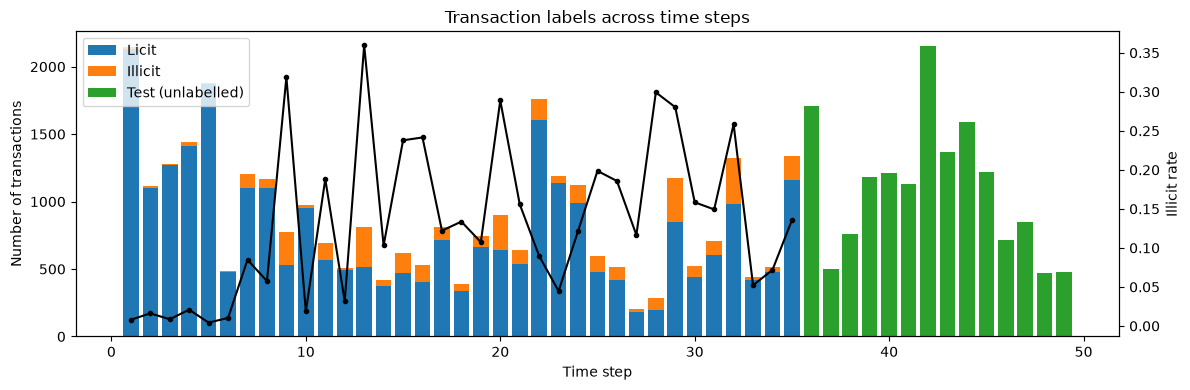

In [4]:
# check class distribution
balance = L["label"].value_counts()
print("Class distribution:")
print(balance)

print("\nClass proportions:")
print(L["label"].value_counts(normalize=True).round(3))


# check illicit rate across time steps
per_step = pd.crosstab(L["time_step"], L["label"])
per_step.columns = ["licit", "illicit"]

per_step["illicit rate"] = per_step["illicit"] / (per_step["licit"] + per_step["illicit"])

print("\nIllicit rate across time steps:")
print(per_step["illicit rate"].describe())


# chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(per_step[["licit", "illicit"]])

cramers_v = np.sqrt(chi2 / per_step[["licit", "illicit"]].values.sum())

print("\nChi-square test:")
print("Chi-square:", round(chi2, 2))
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Cramer's V:", round(cramers_v, 3))


# plot class distribution over time
test_counts = test["time_step"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))

ax.bar(per_step.index, per_step["licit"], label="Licit")
ax.bar(per_step.index, per_step["illicit"], bottom=per_step["licit"], label="Illicit")

ax.bar(test_counts.index, test_counts.values, label="Test (unlabelled)")

ax.set_xlabel("Time step")
ax.set_ylabel("Number of transactions")
ax.legend(loc="upper left")

# add illicit rate on a second y-axis
ax2 = ax.twinx()
ax2.plot(per_step.index, per_step["illicit rate"], color="black", marker=".")
ax2.set_ylabel("Illicit rate")

plt.title("Transaction labels across time steps")
plt.tight_layout()
plt.show()

**Takeaway**
- Only around 22% of the training transactions are labelled, and among these, 11.7% are illicit (3,644 illicit vs 27,591 licit). Since the dataset is imbalanced, accuracy alone would not be a good metric. A model that predicts every transaction as licit would already achieve around 88% accuracy. Hence, I will also look at ROC-AUC, PR-AUC, precision, recall and F1-score when evaluating the models (see Section 3)

- The illicit rate also varies quite a lot across time steps, ranging from 0.4% to 36%, with a median of around 12%. The chi-square test gives a very small p-value, suggesting that time step and transaction label are associated. Cramer's V of 0.32 also indicates that this association is noticeable (effect size). Since the class distribution changes over time, I will use time-based validation to better reflect how the model performs on future transactions

### 1.4 Summary statistics of the features
Next, I look at the distributions of the 165 features, including descriptive statistics, skewness, kurtosis and the percentage of outliers using the IQR method. This shows whether the features are heavily skewed or contain extreme values, which may affect some of the models. I also check the number of unique values to see whether some features might be discrete.

Features with |skewness| > 2: 94
Features with > 5% outliers: 119
Features with <= 10 unique values: 6


,count,mean,std,min,25%,50%,75%,max,skewness,excess kurtosis,% outliers (1.5 IQR),distinct values
feat_1,31235.0,-0.07,0.60,-0.17,-0.17,-0.17,-0.15,25.06,20.56,586.57,16.98,29963
feat_2,31235.0,-0.06,0.57,-0.21,-0.18,-0.16,-0.10,25.67,17.99,489.59,11.50,6759
feat_3,31235.0,-0.20,1.02,-1.76,-1.20,-0.09,1.02,2.13,0.25,-1.60,0.00,8
feat_4,31235.0,0.15,1.56,-0.12,-0.12,-0.05,0.03,49.03,18.10,402.97,13.07,193
feat_5,31235.0,0.04,2.04,-0.06,-0.04,-0.04,-0.04,260.09,83.62,9265.03,31.98,103


,mean,std,skewness,excess kurtosis,% outliers (1.5 IQR),distinct values
min,-0.53,0.01,-3.48,-1.69,0.00,4.0
25%,-0.07,0.95,0.07,-0.10,1.36,1786.0
50%,0.03,1.41,4.21,22.04,16.10,3884.0
75%,0.25,1.62,14.79,324.47,21.99,13539.0
max,1.02,2.50,127.10,19167.58,48.30,30004.0


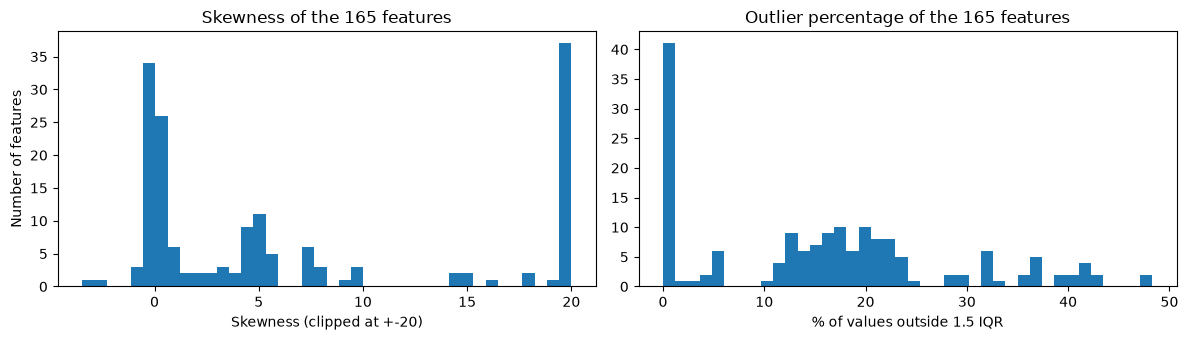

In [5]:
# summary statistics for all 165 features
desc = L[FEATS].describe().T

# check skewness and kurtosis
desc["skewness"] = L[FEATS].skew()
desc["excess kurtosis"] = L[FEATS].kurt()

# calculate outliers using the 1.5 IQR rule
q1 = L[FEATS].quantile(0.25)
q3 = L[FEATS].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = (L[FEATS] < lower) | (L[FEATS] > upper)

desc["% outliers (1.5 IQR)"] = outliers.mean() * 100

# count unique values
desc["distinct values"] = L[FEATS].nunique()

# check how many features have unusual distributions
print("Features with |skewness| > 2:", (desc["skewness"].abs() > 2).sum())
print("Features with > 5% outliers:", (desc["% outliers (1.5 IQR)"] > 5).sum())
print("Features with <= 10 unique values:", (desc["distinct values"] <= 10).sum())

display(desc.head().round(2))

# summary across all 165 features
summary = desc[["mean", "std", "skewness", "excess kurtosis", "% outliers (1.5 IQR)", "distinct values"]]
display(summary.describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))


# plot feature skewness and outlier percentages
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].hist(desc["skewness"].clip(-20, 20), bins=40)
axes[0].set_xlabel("Skewness (clipped at +-20)")
axes[0].set_ylabel("Number of features")
axes[0].set_title("Skewness of the 165 features")

axes[1].hist(desc["% outliers (1.5 IQR)"], bins=40)
axes[1].set_xlabel("% of values outside 1.5 IQR")
axes[1].set_title("Outlier percentage of the 165 features")

plt.tight_layout()
plt.show()

**Takeaway**
- The features seem to be roughly standardised, with means close to 0 and standard deviations mostly around 1 to 2. However, many features are heavily skewed, with 94 out of 165 having an absolute skewness greater than 2. The median excess kurtosis is also quite high at 22, suggesting that many features have heavy tails and extreme values

- 119 features have more than 5% of their values identified as outliers using the 1.5 x IQR rule, but these are anonymised transaction features, so I'm not sure if these values are really errors, so I will keep them for modelling. I also found 6 features with at most 10 unique values, which suggests that some features may be discrete

- These distributions are less of an issue for tree-based models such as LightGBM, since they split features based on thresholds. However, logistic regression and MLPs are more sensitive to feature scales and extreme values. Hence I will apply a quantile transformation to these models and evaluate their performance (see Section 2)

### 1.5 Comparing features between licit and illicit transactions
Next, I compare the feature distributions of licit and illicit transactions to see which features might be useful for classification. Since many features are heavily skewed, I use the Mann-Whitney U test instead of a t-test.

I also calculate the AUC for each feature to see how well it can distinguish between licit and illicit transactions on its own
- AUC of 0.5 means little separation
- AUC closer to 0 or 1 indicate stronger separation in opposite directions

Since there are 165 features, I apply the Benjamini-Hochberg correction to adjust the p-values (when there are many statistical tests, some features may appear significant just by chance, so this helps control the proportion of false positives among the significant results)

Significant features (p < 0.05): 147
Features with AUC outside 0.3 to 0.7: 43
Features with AUC between 0.45 and 0.55: 54


,median licit,median illicit,AUC (effect size),p-value,BH-adjusted p,strength
feature,,,,,,
feat_53,0.7704,-0.4883,0.1432,0.0,0.0,0.3568
feat_55,0.5517,-0.4675,0.1603,0.0,0.0,0.3397
feat_90,0.0671,-0.6942,0.1633,0.0,0.0,0.3367
feat_5,-0.0439,-0.0637,0.1830,0.0,0.0,0.3170
feat_14,-0.0430,-0.0632,0.1831,0.0,0.0,0.3169
feat_66,-0.1631,-0.1631,0.1836,0.0,0.0,0.3164
feat_60,-0.1631,-0.1631,0.1836,0.0,0.0,0.3164
feat_29,-0.1488,-0.1489,0.1868,0.0,0.0,0.3132
feat_23,-0.1488,-0.1489,0.1868,0.0,0.0,0.3132


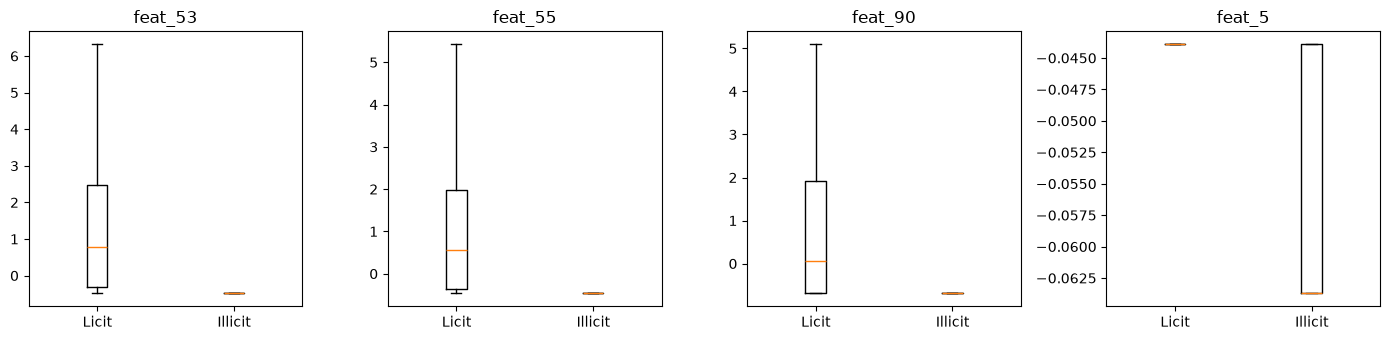

In [6]:
# separate licit and illicit transactions
licit_rows = L[L["label"] == 0]
illicit_rows = L[L["label"] == 1]

# mann-whitney u test for each feature
test_rows = []

for feature in FEATS:
    licit_values = licit_rows[feature]
    illicit_values = illicit_rows[feature]

    u_stat, p_value = stats.mannwhitneyu(illicit_values, licit_values, alternative="two-sided")

    auc = u_stat / (len(illicit_values) * len(licit_values))

    test_rows.append({
        "feature": feature,
        "median licit": licit_values.median(),
        "median illicit": illicit_values.median(),
        "AUC (effect size)": auc,
        "p-value": p_value
    })

class_tests = pd.DataFrame(test_rows)
class_tests = class_tests.set_index("feature")

# adjust p-values for multiple testing
class_tests["BH-adjusted p"] = stats.false_discovery_control(class_tests["p-value"])

# measure how far each feature's AUC is from 0.5
class_tests["strength"] = abs(class_tests["AUC (effect size)"] - 0.5)

# summary of results
print("Significant features (p < 0.05):", (class_tests["BH-adjusted p"] < 0.05).sum())

print("Features with AUC outside 0.3 to 0.7:", (class_tests["strength"] > 0.2).sum())

print("Features with AUC between 0.45 and 0.55:", (class_tests["strength"] < 0.05).sum())

# show features with the largest differences
strongest = class_tests.sort_values("strength", ascending=False)
display(strongest.head(10).round(4))


# boxplots for the 4 strongest features
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for i in range(4):
    feature = strongest.index[i]

    axes[i].boxplot(
        [licit_rows[feature], illicit_rows[feature]],
        tick_labels=["Licit", "Illicit"],
        showfliers=False
    )

    axes[i].set_title(feature)

plt.tight_layout()
plt.show()

**Takeaway**
- After applying the Benjamini-Hochberg correction, 147 out of 165 features are statistically significant. However, since there are over 31,000 labelled transactions, even small differences can be statistically significant. Hence, I also look at the AUC of each feature to understand how well it separates the two classes

- 43 features have an AUC below 0.3 or above 0.7, suggesting that they can distinguish between licit and illicit transactions reasonably well on their own. 54 features have an AUC between 0.45 and 0.55, meaning they have very little individual discriminatory ability

- `feat_53`, `feat_55`, and `feat_90` have some of the strongest differences, with AUC values around 0.14 to 0.16. This means illicit transactions generally have lower values for these features (which can also be seen from the boxplots). Also there are some feature pairs, such as feat_60 and feat_66, that have identical results, so I will check for duplicate or highly correlated features next

- Overall, the results suggest that some of the raw features contain useful information for distinguishing illicit and licit transactions, although I still need to evaluate how well they perform together in a model

### 1.6 Correlations between features
From the previous section, I noticed that some features had very similar results, so I now check whether the features are correlated with each other.

I use Spearman correlation instead of Pearson correlation because many features are heavily skewed. Spearman correlation is based on the ranks of the values, so it is less affected by extreme values. This helps to identify features that may contain similar information.

Total feature pairs: 27225
Pairs with |rho| > 0.9: 133
Pairs with |rho| > 0.95: 93
Features involved in |rho| > 0.95 pairs: 112


feat_24  feat_30    1.000
feat_25  feat_31    1.000
feat_23  feat_29    1.000
feat_22  feat_28    1.000
feat_60  feat_66    1.000
feat_59  feat_65    1.000
feat_61  feat_67    1.000
feat_5   feat_14    1.000
feat_26  feat_32    0.999
feat_27  feat_33    0.999
dtype: float64

feat_24 and feat_30 identical: False
feat_25 and feat_31 identical: False
feat_23 and feat_29 identical: False
feat_22 and feat_28 identical: False
feat_60 and feat_66 identical: False
feat_59 and feat_65 identical: False
feat_61 and feat_67 identical: False
feat_5 and feat_14 identical: False


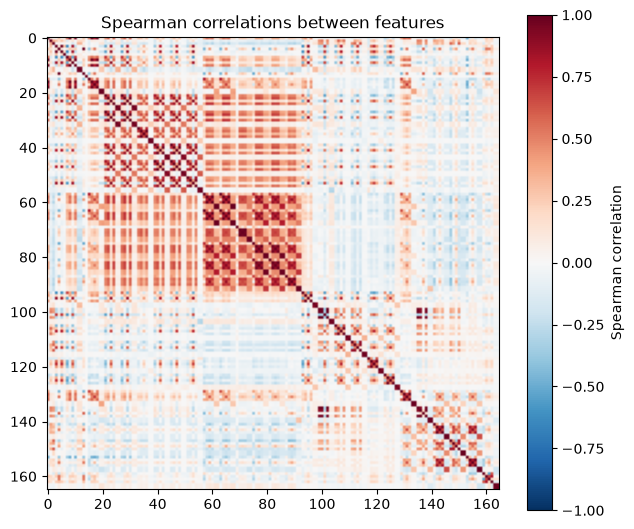

In [7]:
# calculate Spearman correlation between features
corr = L[FEATS].corr(method="spearman")

# keep only the upper triangle to avoid counting pairs twice
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack()

# count highly correlated pairs
print("Total feature pairs:", len(pairs))
print("Pairs with |rho| > 0.9:", (pairs.abs() > 0.9).sum())
print("Pairs with |rho| > 0.95:", (pairs.abs() > 0.95).sum())

strong_pairs = pairs[pairs.abs() > 0.95]

# count how many features are involved in highly correlated pairs
involved = set(strong_pairs.index.get_level_values(0))
involved.update(strong_pairs.index.get_level_values(1))

print("Features involved in |rho| > 0.95 pairs:", len(involved))

# show the most correlated feature pairs
top_pairs = pairs.abs().sort_values(ascending=False)
display(top_pairs.head(10).round(3))

# check if the highly correlated features are identical
feature_pairs = [
    ("feat_24", "feat_30"),
    ("feat_25", "feat_31"),
    ("feat_23", "feat_29"),
    ("feat_22", "feat_28"),
    ("feat_60", "feat_66"),
    ("feat_59", "feat_65"),
    ("feat_61", "feat_67"),
    ("feat_5", "feat_14")
]

for f1, f2 in feature_pairs:
    identical = (L[f1] == L[f2]).all()
    print(f1, "and", f2, "identical:", identical)

# plot correlation heatmap
plt.figure(figsize=(6.5, 5.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.title("Spearman correlations between features")
plt.tight_layout()
plt.show()

**Takeaway**
- There are quite a few highly correlated features. 133 feature pairs with an absolute Spearman correlation above 0.9, including 93 pairs above 0.95. These pairs involve 112 of the 165 features => some features may contain overlapping information

- Some pairs, such as feat_24 and feat_30, have a Spearman correlation of 1.0. However, after comparing their actual values, none of the 8 pairs with correlation 1.0 are exactly identical => they may contain similar information but are not direct duplicates

- These high correlations may cause multicollinearity, which can affect the stability of coefficients in models like logistic regression. However, this is generally less of an issue for tree-based models such as LightGBM, since they can select between correlated features when making splits. When testing logistic regression, I will use regularisation so that I don't need to remove the features based on correlation alone for now (see Section 5)

### 1.7 Comparing labelled and unlabelled transactions
Since around 78% of the training transactions are unlabelled, I want to check whether they have similar feature distributions to the labelled transactions to see if relabelling unknown transactions would be useful.

1. **KS test between labelled and unlabelled transactions**: I use the KS test to compare labelled and unlabelled transactions within each time step (so that any differences found are not simply because the transactions come from different periods). I also apply the Benjamini-Hochberg correction since there are multiple tests.

2. **LightGBM classifier**: Next, I train a LightGBM classifier to distinguish labelled from unlabelled transactions (I chose LightGBM as the earlier EDA showed that many features are skewed and highly correlated, which tree-based models can generally handle well without much preprocessing). I then apply this classifier to the test set to see whether the test transactions are more similar to the labelled or unlabelled training data.

Labelled share per time step:
count    35.000000
mean      0.216237
std       0.047544
min       0.112061
25%       0.179947
50%       0.209741
75%       0.252536
max       0.299118
Name: label, dtype: float64

Total feature-step comparisons: 5775
Significant after BH correction: 92.9 %
Large gaps (KS >= 0.3): 21.8 %


,mean_KS,max_KS,steps_with_large_gap
feature,,,
feat_53,0.533,0.756,34
feat_55,0.513,0.734,33
feat_47,0.422,0.731,30
feat_41,0.416,0.724,30
feat_49,0.416,0.736,30
feat_43,0.411,0.730,30
feat_52,0.365,0.709,23
feat_59,0.359,0.686,22
feat_65,0.359,0.686,22


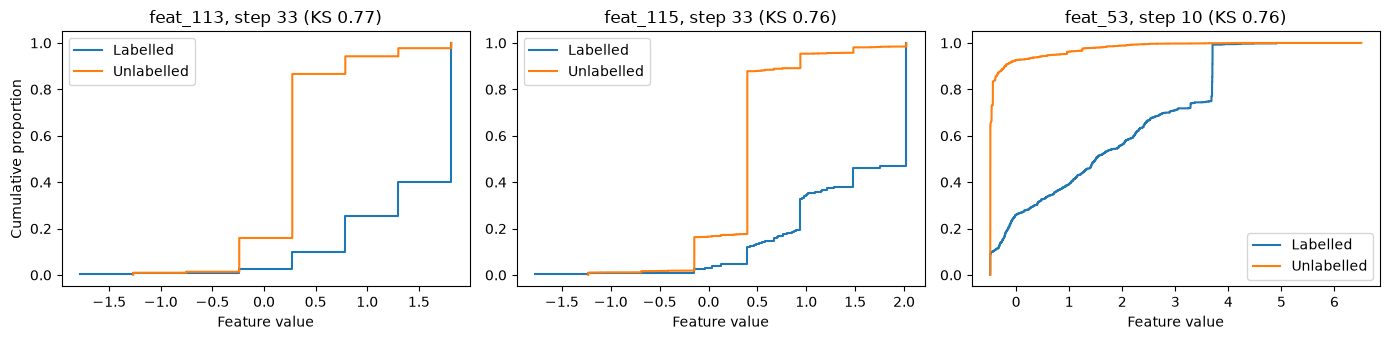

In [8]:
# 1. KS tests within each time step

# compare labelled and unlabelled transactions within each time step
gap_rows = []

for step, step_rows in train.groupby("time_step"):
    known = step_rows[step_rows["label"].notna()]
    unknown = step_rows[step_rows["label"].isna()]

    for feature in FEATS:
        ks_result = stats.ks_2samp(known[feature], unknown[feature])

        gap_rows.append({
            "time_step": step,
            "feature": feature,
            "labelled": len(known),
            "unlabelled": len(unknown),
            "KS statistic": ks_result.statistic,
            "p-value": ks_result.pvalue
        })

label_gaps = pd.DataFrame(gap_rows)

# adjust p-values for multiple testing
label_gaps["BH-adjusted p"] = stats.false_discovery_control(label_gaps["p-value"])

# check which comparisons have large differences
label_gaps["large gap"] = label_gaps["KS statistic"] >= 0.3

# % of labelled transactions in each time step
labelled_share = train.groupby("time_step")["label"].apply(lambda x: x.notna().mean())

print("Labelled share per time step:")
print(labelled_share.describe())

print("\nTotal feature-step comparisons:", len(label_gaps))
print("Significant after BH correction:", round((label_gaps["BH-adjusted p"] < 0.05).mean() * 100, 1), "%")
print("Large gaps (KS >= 0.3):", round(label_gaps["large gap"].mean() * 100, 1), "%")

# summarise the differences for each feature
gap_summary = label_gaps.groupby("feature").agg(
    mean_KS=("KS statistic", "mean"),
    max_KS=("KS statistic", "max"),
    steps_with_large_gap=("large gap", "sum")
)

gap_summary = gap_summary.sort_values("mean_KS", ascending=False)

display(gap_summary.head(10).round(3))


# find the three feature-step combinations with the largest KS statistics
worst = label_gaps.sort_values("KS statistic", ascending=False).head(3)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for i in range(3):
    row = worst.iloc[i]

    step = row["time_step"]
    feature = row["feature"]

    step_rows = train[train["time_step"] == step]

    known = np.sort(step_rows[step_rows["label"].notna()][feature].values)
    unknown = np.sort(step_rows[step_rows["label"].isna()][feature].values)

    # cumulative proportion of observations
    known_y = np.arange(1, len(known) + 1) / len(known)
    unknown_y = np.arange(1, len(unknown) + 1) / len(unknown)

    axes[i].step(known, known_y, where="post", label="Labelled")
    axes[i].step(unknown, unknown_y, where="post", label="Unlabelled")

    axes[i].set_title(f"{feature}, step {step} (KS {row['KS statistic']:.2f})")
    axes[i].set_xlabel("Feature value")
    axes[i].legend()

axes[0].set_ylabel("Cumulative proportion")

plt.tight_layout()
plt.show()

In [9]:
# 2. Compare labelled, unlabelled and test transactions

# 1 = labelled, 0 = unlabelled
is_labelled = train["label"].notna().astype(int)

# train LightGBM to distinguish labelled and unlabelled transactions
labelled_model = lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=0)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

labelled_pred = cross_val_predict(labelled_model, train[FEATS], is_labelled, cv=cv, method="predict_proba")[:, 1]

labelled_auc = roc_auc_score(is_labelled, labelled_pred)
print("Labelled vs unlabelled AUC:", round(labelled_auc, 3))


# fit on all training-period transactions and predict the test set
labelled_model.fit(train[FEATS], is_labelled)

test_pred = labelled_model.predict_proba(test[FEATS])[:, 1]

# compare how many transactions are predicted as labelled-like
print("\nPercentage predicted as labelled-like:")

print("Labelled training rows:", round((labelled_pred[is_labelled == 1] >= 0.5).mean() * 100, 1), "%")

print("Unlabelled training rows:", round((labelled_pred[is_labelled == 0] >= 0.5).mean() * 100, 1), "%")

print("Test rows:", round((test_pred >= 0.5).mean() * 100, 1), "%")

Labelled vs unlabelled AUC: 0.989

Percentage predicted as labelled-like:
Labelled training rows: 87.5 %
Unlabelled training rows: 1.7 %
Test rows: 69.9 %


**Takeaway**
- Only around 11% to 30% of transactions in each time step are labelled. The KS tests show that labelled and unlabelled transactions have quite different feature distributions, with 93% of the feature-step comparisons being statistically significant after BH correction and 22% having a KS statistic of at least 0.3

- The largest differences are seen in `feat_53` and `feat_55`, with average KS statistics above 0.5 and large differences in 33 to 34 of the 35 time steps. Features 41 to 49 also show relatively large differences. Interestingly, `feat_53` and `feat_55` were also among the strongest features for distinguishing licit and illicit transactions in Section 1.5. Overall, this suggests that the labelled transactions may not be representative of the entire training dataset, especially since some of the features that differ the most are also useful for fraud classification

- The LightGBM classifier achieved an AUC of 0.989 when distinguishing labelled from unlabelled transactions. It predicts 87.5% of the labelled transactions as labelled-like but only 1.7% of the unlabelled ones, so the two groups clearly look different. When applied to the test set, 69.9% of test transactions were predicted as labelled-like **BUT** if the test set had the same mix as the training period (22% labelled), I would expect only about 21% of them to look labelled-like (0.22 x 87.5% + 0.78 x 1.7%). Since the actual share is much higher (69.9% vs 21%), the test set seems to be more similar to the labelled training population, so I will only train on labelled transactions for the prediction task

- Since the unlabelled transactions have different feature distributions, relabelling these unlabelled transactions might introduce additional bias or noise. Hence, I decided not to relabel them for now. However, I will still use the unlabelled transactions as part of the graph and for PCA (see Section 4), without assigning them fraud labels

### 1.8 Analysing the transaction graph
Before creating graph features, I want to understand how the transactions are connected and whether the graph contains useful information for identifying illicit transactions.
1. **Connections between training and test transactions**: First, I check whether training and test transactions are connected, and how many neighbours have available features. This is important because graph features may be calculated differently if some neighbouring transactions are missing from the dataset.

2. **Homophily and number of connections**: Next, I check whether illicit transactions tend to be connected to other illicit transactions (homophily). I use the chi-square test and odds ratio to check the association between the labels of connected transactions. I also use the (2xy) method (Lecture 8) to compare the observed proportion of cross-label edges with what would be expected under random mixing. I also compare the in-degree, out-degree and total degree of licit and illicit transactions to see whether they have different numbers of connections.

3. **Overall network structure**: Lastly, I look at some of the network cohesion measures covered in Lecture 8 (e.g. connected components, reciprocity, density and clustering coefficient) to better understand the overall structure of the transaction graph and which graph-based features might be worth exploring later.

In [10]:
# 1. Connections between training and test transactions

# match transaction IDs to their time steps
step_of = pd.concat([
    train[["txId", "time_step"]],
    test[["txId", "time_step"]]
]).set_index("txId")["time_step"]

# check if connected transactions are from the same time step
known = edges[
    edges["txId1"].isin(step_of.index) &
    edges["txId2"].isin(step_of.index)
]

same_step = known["txId1"].map(step_of) == known["txId2"].map(step_of)

print("Edges within the same time step:", round(same_step.mean() * 100, 1), "%")


# check for edges between training and test transactions
train_ids = set(train["txId"])
test_ids = set(test["txId"])

train_to_test = edges["txId1"].isin(train_ids) & edges["txId2"].isin(test_ids)
test_to_train = edges["txId1"].isin(test_ids) & edges["txId2"].isin(train_ids)

cross = train_to_test | test_to_train

print("Edges between train and test:", cross.sum())


# add reversed edges to count neighbours in both directions
reverse_edges = edges[["txId2", "txId1"]].copy()
reverse_edges.columns = ["txId1", "txId2"]

both = pd.concat([edges, reverse_edges], ignore_index=True)
both.columns = ["a", "b"]

# check whether each neighbour has available features
both["has_features"] = both["b"].isin(train_ids | test_ids)

coverage = both.groupby("a")["has_features"].mean()

train_coverage = coverage.reindex(L["txId"]).mean()
test_coverage = coverage.reindex(test["txId"]).mean()

print("Labelled training neighbour coverage:", round(train_coverage * 100, 1), "%")
print("Test neighbour coverage:", round(test_coverage * 100, 1), "%")

Edges within the same time step: 100.0 %
Edges between train and test: 0
Labelled training neighbour coverage: 100.0 %
Test neighbour coverage: 60.9 %


In [11]:
# 2. Homophily and number of connections

# get the labels of training transactions
label_of = dict(zip(L["txId"], L["label"]))

# keep edges where both transactions have known labels
ll = edges[edges["txId1"].isin(label_of) & edges["txId2"].isin(label_of)]

# compare the labels of connected transactions
payer_labels = ll["txId1"].map(label_of)
receiver_labels = ll["txId2"].map(label_of)

edge_labels = pd.crosstab(payer_labels, receiver_labels)
edge_labels.index.name = "payer"
edge_labels.columns.name = "receiver"

display(edge_labels)


# chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(edge_labels)

# odds ratio
odds_ratio = (edge_labels.loc[1, 1] * edge_labels.loc[0, 0]) / (edge_labels.loc[1, 0] * edge_labels.loc[0, 1])

print("Chi-square:", round(chi2, 2))
print("p-value:", p_value)
print("Odds ratio:", round(odds_ratio, 2))


# probability of an illicit receiver
p_illicit_payer = edge_labels.loc[1, 1] / edge_labels.loc[1].sum()
p_licit_payer = edge_labels.loc[0, 1] / edge_labels.loc[0].sum()

print("P(illicit receiver | illicit payer):", round(p_illicit_payer, 3))
print("P(illicit receiver | licit payer):", round(p_licit_payer, 3))
print("Overall illicit rate:", round(L["label"].mean(), 3))


# compare observed cross-label edges with expected proportion
x_share = 1 - L["label"].mean()
y_share = L["label"].mean()

cross_label = edge_labels.loc[0, 1] + edge_labels.loc[1, 0]
r_cross = cross_label / edge_labels.values.sum()

print("Observed cross-label proportion:", round(r_cross, 3))
print("Expected proportion (2xy):", round(2 * x_share * y_share, 3))


# compare the number of connections between classes
position = gi[L.index.values]

connections = pd.DataFrame({
    "in-degree": in_degree[position],
    "out-degree": out_degree[position],
    "total degree": degree[position],
    "label": L["label"].values
})

display(connections.groupby("label").median())

licit_degree = connections[connections["label"] == 0]["total degree"]
illicit_degree = connections[connections["label"] == 1]["total degree"]

u_stat, p_value = stats.mannwhitneyu(illicit_degree, licit_degree)
degree_auc = u_stat / (len(illicit_degree) * len(licit_degree))

print("Mann-Whitney p-value:", p_value)
print("Degree AUC:", round(degree_auc, 3))

receiver,0.0,1.0
payer,,
0.0,21772,597
1.0,674,857


Chi-square: 7117.48
p-value: 0.0
Odds ratio: 46.37
P(illicit receiver | illicit payer): 0.56
P(illicit receiver | licit payer): 0.027
Overall illicit rate: 0.117
Observed cross-label proportion: 0.053
Expected proportion (2xy): 0.206


,in-degree,out-degree,total degree
label,,,
0.0,1.0,1.0,2.0
1.0,1.0,1.0,1.0


Mann-Whitney p-value: 0.0
Degree AUC: 0.372


In [12]:
# 3. Overall graph structure

# connected components
steps_in_component = pd.Series(nodes["time_step"].values).groupby(COMPONENT[gi]).nunique()
component_size = np.bincount(COMPONENT)

print("Connected components:", n_components)
print("Time steps:", nodes["time_step"].nunique())
print("Components containing multiple time steps:", (steps_in_component > 1).sum())
print("Smallest component:", component_size.min())
print("Largest component:", component_size.max())


# reciprocal edges
reciprocal = A.multiply(AT).sum()
print("Reciprocal edges:", int(reciprocal))


# triangles and clustering coefficient
triangles = np.asarray((U @ U).multiply(U).sum(axis=1)).ravel() / 2

clustering = np.where(degree > 1, 2 * triangles / np.maximum(degree * (degree - 1), 1), 0)

print("Total triangles:", int(triangles.sum() / 3))
print("Mean clustering coefficient:", round(clustering.mean(), 4))
print("Transactions in at least one triangle:", round((triangles > 0).mean() * 100, 1), "%")


# compare number of edges with a forest
print("Undirected edges:", int(U.sum() / 2))
print("Edges in a forest with the same components:", N - n_components)

Connected components: 49
Time steps: 49
Components containing multiple time steps: 0
Smallest component: 1089
Largest component: 7880
Reciprocal edges: 0
Total triangles: 8623
Mean clustering coefficient: 0.0138
Transactions in at least one triangle: 3.5 %
Undirected edges: 234355
Edges in a forest with the same components: 203720


**Takeaway**
- The transaction graph is separated by time step, with no edges connecting training and test transactions => there is no way to directly use known labels from training transactions to predict test transactions through their connections

- Labelled training transactions have almost all their neighbours visible, but test transactions only have around 61% visible. This means that some neighbours of test transactions appear in the edge list but do not have corresponding feature records. Since based on Section 1.7, the test transactions appeared more similar to the labelled training population, this suggests that the test set may represent a selected subset of transactions rather than the entire graph => !!! need to take note of this when calculating neighbour features, so that the information used is consistent between training and testing (i.e. using visible neighbours only)

- There is strong evidence of homophily. When the payer is illicit, the receiver is illicit around 56% of the time, compared to only 2.7% when the payer is licit (the overall illicit rate is 11.7%). The chi-square test gives a very small p-value (χ² ≈ 7,117), and the odds ratio is around 46, suggesting a strong association between the labels of connected transactions. Using the 2xy method from Lecture 8, I also found that only 5.3% of labelled-labelled edges connect transactions with different labels, compared to an expected 20.6% under a simple random-mixing assumption

- Looking at the overall graph structure, there are no reciprocal edges and the clustering coefficient is close to 0. There are only around 8,600 triangles among approximately 204,000 transactions, suggesting that the graph is mostly made up of chains and branches rather than tightly connected groups => should explore other graph features based on neighbour relationships and paths, such as PageRank, instead of features based on clustering

- Illicit transactions also tend to have slightly fewer connections than licit transactions, with median degrees of 1 and 2 respectively. The Mann-Whitney AUC of around 0.37 suggests that the number of connections alone provides some information for distinguishing the 2 classes, although it is not a particularly strong feature.

- Overall, these findings suggest that graph information could be useful for detecting illicit transactions, especially because connected transactions tend to have similar labels. Hence, I would want to explore graph-based features and models (see Sections 4 and 7)

### 1.9 Illicit transaction behaviour over time
Since the model is trained on earlier time steps and tested on later ones, I want to check whether illicit transactions show similar patterns over time, or whether new patterns appear that the model may not have seen before.
1. **Comparing illicit transactions with earlier time steps**: First, I use KNN to compare illicit transactions at each time step with transactions from earlier time steps. I look at the average distance to their 20 nearest earlier illicit transactions and the proportion whose 20 nearest earlier transactions are mostly licit. I use a quantile transformation first so that features with extreme values do not dominate the distance calculations. I also check the size of connected groups of illicit transactions within each time step, to see whether illicit activity tends to occur in smaller groups or larger connected clusters.

2. **Analysing large illicit clusters**: Next, I compare transactions in these large clusters with other illicit and licit transactions. I look at how similar they are to transactions from steps 1-21 and whether the large clusters across different time steps share similar feature patterns. I also check for possible peel-chain-like patterns (repeatedly splitting funds into a smaller payment and a remaining amount that continues to another transaction). Since I only have the transaction graph and anonymised features, I use 1 incoming and 2 outgoing graph connections as an approximation of this pattern.

,illicit,distance to earlier illicit,% that look licit,largest illicit cluster
step,,,,
8,67,9.5,31.3,6
9,248,6.7,8.9,3
10,18,5.4,33.3,3
11,131,4.6,6.1,2
12,16,9.6,12.5,1
13,291,4.1,3.8,4
14,43,6.7,9.3,2
15,147,4.3,2.7,3
16,128,4.2,3.9,3


Steps with large illicit clusters (>= 40): [24, 29, 31, 32]


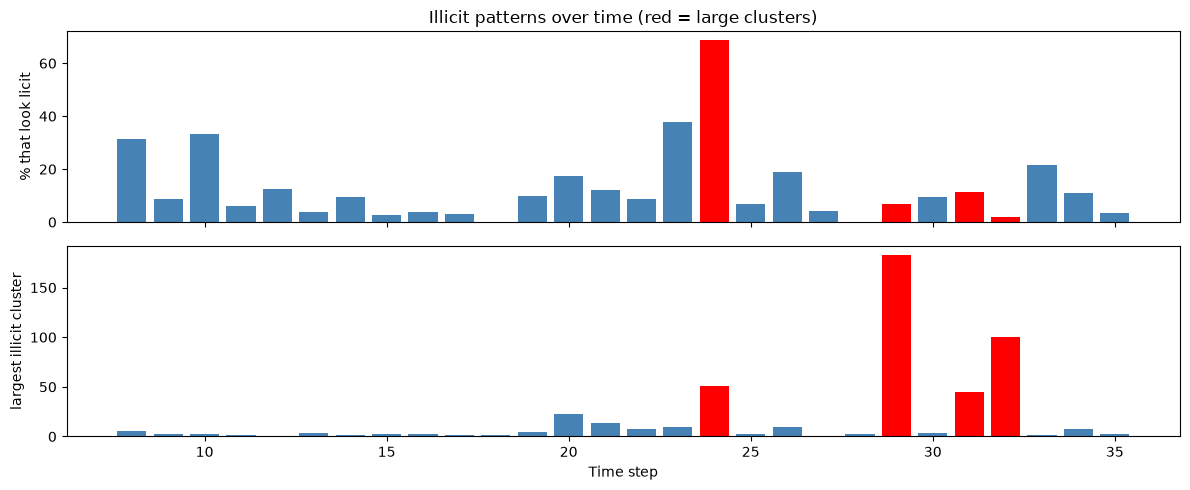

In [13]:
# 1. Comparing illicit transactions across time steps

# transform the features so extreme values affect distances less
transformer = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)

Z_lab = transformer.fit_transform(L[FEATS])

y_lab = L["label"].values
step_lab = L["time_step"].values


# find connected groups of illicit transactions for each time step
cluster_tables = []

for t, step_rows in L.groupby("time_step"):
    illicit = step_rows[step_rows["label"] == 1]
    idx = pd.Index(illicit["txId"])

    # keep edges between illicit transactions
    step_edges = edges[edges["txId1"].isin(idx) & edges["txId2"].isin(idx)]

    step_src = idx.get_indexer(step_edges["txId1"])
    step_dst = idx.get_indexer(step_edges["txId2"])

    M = sp.csr_matrix((np.ones(len(step_edges)), (step_src, step_dst)), shape=(len(idx), len(idx)))

    # find connected components
    n_clusters, component = connected_components(M, directed=False)
    sizes = np.bincount(component)

    cluster_tables.append(pd.DataFrame({
        "cluster": [f"{t}_{c}" for c in component],
        "cluster size": sizes[component]
    }, index=illicit.index))

ILLICIT_CLUSTER = pd.concat(cluster_tables)
cluster_size = ILLICIT_CLUSTER["cluster size"].reindex(L.index).values


# compare illicit transactions with earlier transactions
rows = []

for t in range(8, 36):
    now = (step_lab == t) & (y_lab == 1)
    earlier = step_lab < t

    # 20 nearest earlier illicit transactions
    knn_illicit = NearestNeighbors(n_neighbors=20)
    knn_illicit.fit(Z_lab[earlier & (y_lab == 1)])

    distance, _ = knn_illicit.kneighbors(Z_lab[now])

    # 20 nearest earlier transactions, regardless of label
    knn_all = NearestNeighbors(n_neighbors=20)
    knn_all.fit(Z_lab[earlier])

    _, nearest = knn_all.kneighbors(Z_lab[now])

    neighbour_labels = y_lab[earlier][nearest]
    licit_share = (neighbour_labels == 0).mean(axis=1)

    rows.append({
        "step": t,
        "illicit": int(now.sum()),
        "distance to earlier illicit": np.median(distance.mean(axis=1)),
        "% that look licit": 100 * (licit_share > 0.8).mean(),
        "largest illicit cluster": int(np.nanmax(cluster_size[now]))
    })

by_step = pd.DataFrame(rows).set_index("step")

display(by_step.round(1))


# find time steps with illicit clusters of at least 40 transactions
CLUSTER_STEPS = []

for t in L["time_step"].unique():
    mask = (L["time_step"] == t) & (cluster_size >= 40)

    if mask.any():
        CLUSTER_STEPS.append(int(t))

CLUSTER_STEPS = sorted(CLUSTER_STEPS)

print("Steps with large illicit clusters (>= 40):", CLUSTER_STEPS)


# plot illicit patterns across time
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

for i, column in enumerate(["% that look licit", "largest illicit cluster"]):
    for step in by_step.index:
        if step in CLUSTER_STEPS:
            colour = "red"
        else:
            colour = "steelblue"

        axes[i].bar(step, by_step.loc[step, column], color=colour)

    axes[i].set_ylabel(column)

axes[1].set_xlabel("Time step")
axes[0].set_title("Illicit patterns over time (red = large clusters)")

plt.tight_layout()
plt.show()

In [14]:
# 2. Analysing large illicit clusters

# identify illicit transactions in large clusters
in_big_cluster = pd.Series((cluster_size >= 40) & np.isin(step_lab, CLUSTER_STEPS), index=L.index)

early = step_lab <= 21
later = step_lab >= 22


# separate transactions into 3 groups
group = pd.Series("illicit, other", index=L.index)
group[y_lab == 0] = "licit"
group[in_big_cluster] = "illicit, large clusters"


# check for possible peel-chain-like structures
peel = (in_degree[position] == 1) & (out_degree[position] == 2)


# compare later transactions with those from steps 1-21
knn = NearestNeighbors(n_neighbors=20)
knn.fit(Z_lab[early])

distance, nearest = knn.kneighbors(Z_lab[later])

compare = pd.DataFrame({
    "group": group[later].values,
    "proportion of 20 nearest (steps 1-21) illicit": y_lab[early][nearest].mean(axis=1),
    "distance to 20 nearest (steps 1-21)": distance.mean(axis=1),
    "% with peel shape": 100 * peel[later]
})

summary = compare.groupby("group").agg({
    "proportion of 20 nearest (steps 1-21) illicit": "median",
    "distance to 20 nearest (steps 1-21)": "median",
    "% with peel shape": "mean"
})

display(summary.round(3))


# compare average feature profiles using cosine similarity
Z_frame = pd.DataFrame(Z_lab, columns=FEATS, index=L.index)

profiles = {}

for t in CLUSTER_STEPS:
    mask = in_big_cluster & (L["time_step"] == t)
    profiles[f"large clusters, step {t}"] = Z_frame[mask].mean()

profiles["illicit, steps 1-21"] = Z_frame[early & (y_lab == 1)].mean()
profiles["licit, steps 1-21"] = Z_frame[early & (y_lab == 0)].mean()

profile_table = pd.DataFrame(profiles)

# normalise the profiles for cosine similarity
profile_table = profile_table / np.linalg.norm(profile_table, axis=0)

similarity = profile_table.T @ profile_table

display(similarity.round(2))

,proportion of 20 nearest (steps 1-21) illicit,distance to 20 nearest (steps 1-21),% with peel shape
group,,,
"illicit, large clusters",0.0,11.458,11.873
"illicit, other",1.0,6.456,3.013
licit,0.0,16.285,7.078


,"large clusters, step 24","large clusters, step 29","large clusters, step 31","large clusters, step 32","illicit, steps 1-21","licit, steps 1-21"
"large clusters, step 24",1.00,0.99,0.97,0.99,0.53,0.67
"large clusters, step 29",0.99,1.00,0.99,1.00,0.52,0.67
"large clusters, step 31",0.97,0.99,1.00,0.99,0.51,0.65
"large clusters, step 32",0.99,1.00,0.99,1.00,0.52,0.67
"illicit, steps 1-21",0.53,0.52,0.51,0.52,1.00,0.78
"licit, steps 1-21",0.67,0.67,0.65,0.67,0.78,1.00


**Takeaway**
- For most time steps, illicit transactions appear relatively similar to earlier illicit transactions, with distances to their nearest earlier illicit neighbours generally around 4 to 5. The largest connected illicit clusters are also usually smaller than 10 transactions

- However, for steps 23 and 24, their distances to earlier illicit transactions increases to 21.9 and 25.0 respectively. Around 37.7% and 68.6% of illicit transactions in these steps also have mostly licit transactions among their nearest earlier neighbours. This suggests that some new illicit transaction patterns may have appeared around these time steps

- I also found large connected groups of illicit transactions in steps 24, 29, 31 and 32, with the largest clusters containing 51, 183, 45 and 100 transactions respectively. Although step 29 has the largest cluster, only 6.7% of its illicit transactions have mostly licit nearest neighbours when compared with all earlier steps (1-28). This could be because similar patterns had already appeared in earlier periods, particularly around steps 23-24

- To investigate this further, I compared the large-cluster transactions specifically against the earlier period of steps 1-21. Their median proportion of illicit transactions among the 20 nearest earlier neighbours is 0, compared with 1 for other illicit transactions. This suggests that the large-cluster transactions differ from the illicit patterns seen in the earlier period. I also found that 11.9% have a possible peel-chain-like graph pattern, compared with 3.0% of other illicit transactions. However, this only refers to transactions with 1 incoming and 2 outgoing graph connections, so this is not confirm peel-chain activity

- The 4 large clusters also have very similar average feature profiles, with cosine similarities ranging from 0.97 to 1.00. Their similarity with illicit transactions from steps 1-21 is lower (0.51-0.53) than with licit transactions from the same period (0.65-0.67) => these clusters share similar feature patterns that differ from earlier illicit transactions

- Overall, the findings suggest that some different illicit transaction patterns may have appeared around steps 23-24 and continued appearing in later steps. Since models trained only on earlier time steps may not have encountered these patterns, I will examine their performance on these time steps separately during evaluation

### 1.10 Checking for changes in the test period
Since the test data comes from later time steps, I want to see whether its patterns are similar to the training data or whether there are any noticeable changes.
1. **Comparing test transactions with earlier training transactions**: First, I use KNN to calculate the distance between transactions in later time steps and their 20 nearest labelled transactions from steps 1-28. This helps me see whether the test transactions become increasingly different from the earlier training data.

2. **Checking for long transaction chains**: Next, I check whether the test period contains long connected chains similar to the large illicit clusters identified in Section 1.9. I remove connections involving high-degree nodes (> 3 connections) as these hubs could link separate chains together. Then, I compare the chain sizes across the training and test periods.

3. **Comparing feature and graph-structure changes**: Lastly, I use LightGBM to check how easily different time periods can be distinguished from each other. I compare steps 22-28 against 29-35, and test steps 36-42 against 43-49. Similar to Section 1.7, I chose LightGBM because it can handle skewed and highly correlated features without much preprocessing. I repeat the comparison using 2 sets of inputs: the 20 strongest individual features identified earlier, and graph-structure features such as degree and the number of two-hop neighbours. A higher ROC-AUC means the classifier can distinguish the two periods more easily, suggesting greater differences in their feature distributions. This helps me examine whether the individual transaction features or graph structure change more over time

In [15]:
# 1. Distance from earlier training transactions

# use steps 1-28 as the reference period
reference = L[L["time_step"] <= 28]

# transform features before calculating distances
qt_ref = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)

X_ref = qt_ref.fit_transform(reference[FEATS])

# fit KNN using the earlier labelled transactions
nn_ref = NearestNeighbors(n_neighbors=20)
nn_ref.fit(X_ref)

# compare later transactions with the reference period
later_rows = nodes[nodes["visible"] & (nodes["time_step"] >= 29)]

X_later = qt_ref.transform(later_rows[FEATS])

distance, _ = nn_ref.kneighbors(X_later)

# median distance for each time step
novelty = pd.Series(distance.mean(axis=1), index=later_rows.index)
novelty = novelty.groupby(later_rows["time_step"]).median()

display(novelty.round(2).to_frame("median distance").T)

# compare the three periods
print("Training steps 29-35:", round(novelty.loc[29:35].mean(), 2))
print("Test steps 36-42:", round(novelty.loc[36:42].mean(), 2))
print("Test steps 43-49:", round(novelty.loc[43:49].mean(), 2))

time_step,29,30,31,32,33,34,35,36,37,38,...,40,41,42,43,44,45,46,47,48,49
median distance,15.56,14.94,16.43,17.24,16.52,18.29,16.56,19.97,16.61,15.99,...,18.6,18.23,18.07,26.32,18.68,18.58,19.58,18.88,18.98,17.17


Training steps 29-35: 16.51
Test steps 36-42: 17.61
Test steps 43-49: 19.74


In [16]:
# 2. Checking for long chains

# remove edges involving nodes with more than 3 connections
low_degree = (degree[src] <= 3) & (degree[dst] <= 3)

chain_src = src[low_degree]
chain_dst = dst[low_degree]

# create a graph using the remaining edges
chain_graph = sp.csr_matrix((np.ones(len(chain_src)), (chain_src, chain_dst)), shape=(N, N))

# find connected components
n_chains, CHAIN = connected_components(chain_graph, directed=False)

# match chain information back to transactions
nodes["chain"] = CHAIN[gi]

# count visible transactions in each chain
chain_counts = nodes.loc[nodes["visible"], "chain"].value_counts()

nodes["chain_size"] = nodes["chain"].map(chain_counts).fillna(0)

# update labelled and test data
L = nodes[(nodes["split"] == "train") & nodes["label"].notna()]
T = nodes[nodes["split"] == "test"]


# long chain = at least the 25th percentile of chain sizes in the large illicit clusters from Section 1.9
size_cut = L.loc[in_big_cluster, "chain_size"].quantile(0.25)

# identify visible transactions belonging to long chains
long_chain = nodes["visible"] & (nodes["chain_size"] >= size_cut)

# % of transactions in long chains per time step
share = long_chain[nodes["visible"]].groupby(nodes.loc[nodes["visible"], "time_step"]).mean() * 100

other_steps = []

for step in range(22, 36):
    if step not in CLUSTER_STEPS:
        other_steps.append(step)

print("Minimum chain size:", round(size_cut, 0))

print(share.loc[22:49].round(1).to_frame("% in long chains").T.to_string())

print("Large-cluster steps:", round(share.loc[CLUSTER_STEPS].mean(), 1), "%")
print("Other training steps:", round(share.loc[other_steps].mean(), 1), "%")
print("Test steps:", round(share.loc[36:49].mean(), 1), "%")

Minimum chain size: 78.0
time_step           22   23    24   25   26   27   28    29   30   31   32   33   34   35   36   37   38   39   40   41   42   43   44   45   46   47   48   49
% in long chains  12.6  6.8  26.6  0.0  0.0  0.0  0.0  25.6  0.0  0.0  8.7  0.0  0.0  6.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
Large-cluster steps: 15.2 %
Other training steps: 2.5 %
Test steps: 0.0 %


In [17]:
# 3. Comparing changes in features and graph structure

# create graph structure features for all transactions (they describe how each transaction is connected to others)
STRUCTURE = pd.DataFrame({
    "in_deg": in_degree[gi],
    "out_deg": out_degree[gi],
    "deg": degree[gi],
    "nb_deg_sum": (U @ degree)[gi],
    "two_hop": np.asarray(TWO_HOP.sum(axis=1)).ravel()[gi],
    "in_out_ratio": (in_degree[gi] + 1) / (out_degree[gi] + 1)
}, index=nodes.index)


# only use transactions with available features
vis = nodes[nodes["visible"]]

# 1.10 part 1 above showed a large jump in distance at step 43, so compare test steps 36-42 with steps 43-49
# also compare training steps 22-28 with 29-35 as a reference
period_pairs = {
    "ordinary, 22-28 vs 29-35": (
        vis[(vis["split"] == "train") & vis["time_step"].between(22, 28)],
        vis[(vis["split"] == "train") & vis["time_step"].between(29, 35)]
    ),
    "test, 36-42 vs 43-49": (
        vis[vis["time_step"].between(36, 42)],
        vis[vis["time_step"].between(43, 49)]
    )
}

# compare changes in the 20 strongest transaction features against changes in graph structure
inputs = {
    "20 strongest features": (nodes, list(strongest.index[:20])),
    "graph structure": (STRUCTURE, list(STRUCTURE.columns))
}

stability = {}

for period, (a, b) in period_pairs.items():
    for block, (frame, cols) in inputs.items():

        # combine transactions from both periods
        X = pd.concat([frame.loc[a.index, cols], frame.loc[b.index, cols]])

        # 0 = earlier period, 1 = later period
        y = np.concatenate([np.zeros(len(a)), np.ones(len(b))])

        # train LightGBM to predict which period a transaction belongs to
        model = lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=0)

        # use 5-fold cross-validation to evaluate period classification
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

        predictions = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]

        # higher ROC-AUC = easier to distinguish the periods = greater differences in their feature distributions
        # ROC-AUC around 0.5 = periods are difficult to distinguish
        stability[period, block] = roc_auc_score(y, predictions)

# compare how much transaction features and graph structure change
stability_results = pd.Series(stability).unstack()
display(stability_results.round(3))

,20 strongest features,graph structure
"ordinary, 22-28 vs 29-35",0.926,0.738
"test, 36-42 vs 43-49",0.902,0.687


**Takeaway**
- The test transactions appear to become more different from the earlier training data over time. The average median distance increases from 16.5 in training steps 29-35 to 17.6 in test steps 36-42, and then to 19.7 in steps 43-49. Step 43 is the most different, with a distance of 26.3 => there may be a noticeable change in the feature distributions at around step 43

- I also checked whether the test transactions belong to long connected groups similar to the large illicit clusters found in Section 1.9. While an average of 15.2% of transactions in the earlier large-cluster steps belonged to these long groups, none of the visible test transactions met the same threshold => the test period does not show the same long-chain pattern under my chosen definition, although it may still contain other types of unusual graph structures

- When comparing the two time periods using LightGBM, the 20 strongest individual features gave AUCs of around 0.93 for training steps 22-28 against 29-35, and 0.90 for test steps 36-42 against 43-49. However, using only graph-structure features gave lower AUCs of around 0.74 and 0.69 respectively => the individual transaction features change more noticeably between periods than the graph structure features I tested

- Overall, these findings suggest that the test period has some differences from the training period, particularly around step 43. Since the graph-structure features appear relatively more stable across time, it could help the models generalise better to later transactions

### 1.11 Summary of the EDA

| Finding | Evidence from EDA | How I use this later |
|---|---|---|
| The classes are imbalanced, and the illicit rate changes over time | Only 11.7% of labelled transactions are illicit. The illicit rate ranges from 0.4% to 36% across time steps (χ² ≈ 3,176, Cramer's V = 0.32) | Use ROC-AUC, PR-AUC, precision, recall and F1 instead of relying on accuracy alone. Also use time-based validation to reflect the test period (Section 3) |
| Many features are skewed and contain extreme values | 94 of 165 features have absolute skewness above 2, and 119 have more than 5% outliers based on the IQR rule | Keep the outliers since they may contain useful information. Apply quantile transformation for logistic regression and MLP, but not tree-based models (Section 2) |
| Some raw features are useful for distinguishing licit and illicit transactions | 147 features are statistically significant after BH correction, while 43 have an individual AUC below 0.3 or above 0.7 | Keep all 165 raw features initially and let the models learn how to combine them (Sections 3 and 5) |
| Many features are highly correlated | 93 feature pairs have absolute Spearman correlation above 0.95, although the pairs checked are not exactly identical | Keep the correlated features for now, since tree-based models can generally handle them. Use regularisation for logistic regression (Sections 5 and 6) |
| Labelled and unlabelled transactions have different feature distributions | 22% of feature-step comparisons have KS >= 0.3. LightGBM achieves AUC 0.989 when distinguishing the two groups, and around 70% of test transactions are predicted as labelled-like | Train using labelled transactions only rather than assigning labels to the unlabelled ones. Still use unlabelled transactions for graph analysis and PCA (Sections 2 and 4) |
| Training and test transactions are not directly connected | All graph edges stay within their own time step, and only around 61% of test transactions' neighbours are visible | Calculate neighbour features using visible neighbours so the same method can be applied to training and test transactions (Section 4) |
| Connected transactions tend to have similar labels | χ² ≈ 7,117 and odds ratio ≈ 46. Only 5.3% of labelled-labelled edges connect different labels, compared with 20.6% expected under random mixing | Explore neighbour-based features and collective classification, since neighbouring transactions may provide useful information (Sections 4 and 7) |
| The graph has very little local clustering | No reciprocal edges, 8,623 triangles and a clustering coefficient of 0.014 | Explore graph measures such as degree, two-hop neighbours and PageRank to capture different aspects of the graph structure instead of focusing on clustering-based measures (Sections 4 and 7) |
| Some unusual illicit patterns appear in later training steps | Steps 23-24 have much higher distances to earlier illicit transactions. Large illicit clusters also appear in steps 24, 29, 31 and 32, with similar average feature profiles | Evaluate model performance separately on the large-cluster steps to see how well models handle these patterns (Sections 3 and 9) |
| The test period shows further changes, especially around step 43 | Distance to earlier training transactions jumps at step 43. No visible test transactions meet my long-chain threshold, while the graph-structure features are less able to distinguish time periods than the raw features (AUC 0.69 vs 0.90) | Consider graph-based models or graph information for the final model (Sections 7 and 9) |

## 2. Data Preprocessing
Based on the findings from my EDA, I made the following preprocessing choices:
- **Missing values**: There are no missing values in the original 165 features. However, some neighbour features created in Section 4 may be missing when a transaction has no visible neighbours. Tree-based models can handle these missing values directly, while I use median imputation for logistic regression and MLP

- **Scaling**: I do not apply scaling for tree-based models since they are generally unaffected by the scale of the features. For logistic regression and the MLP, I use a quantile transformation to make the feature distributions closer to normal, as many features were highly skewed in Section 1.4. I include this transformation within the model pipeline so that it is fitted only on the training data for each fold, avoiding data leakage into validation

- **Outliers**: I decided not to remove outliers, since Section 1.4 showed that 119 features have more than 5% of their values outside the 1.5 x IQR bounds. This suggests that extreme values are common in the dataset, and removing them could mean losing useful transaction information. Since the features are annonymised, I'm also not sure if these outliers are really errors

- **Labelled and unlabelled transactions**: I use only labelled transactions to train the supervised models. Section 1.7 showed noticeable differences between labelled and unlabelled transactions, so I do not assume that the unlabelled ones can be safely assigned labels. However, I still use them for graph-based features in Section 4.2 and PCA in Section 4.3, where their actual labels are not needed

I also check how much the quantile transformation reduces skewness in the original features

In [18]:
# check whether quantile transformation reduces feature skewness
quantile = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)

transformed = pd.DataFrame(quantile.fit_transform(L[FEATS]), columns=FEATS)

# compare skewness before and after transformation
skew_before = L[FEATS].skew().abs()
skew_after = transformed.skew().abs()

print("Median |skewness| before:", round(skew_before.median(), 2))
print("Median |skewness| after:", round(skew_after.median(), 2))

print("Features with |skewness| > 2 before:", (skew_before > 2).sum())
print("Features with |skewness| > 2 after:", (skew_after > 2).sum())

Median |skewness| before: 4.21
Median |skewness| after: 0.23
Features with |skewness| > 2 before: 94
Features with |skewness| > 2 after: 5


**Takeaway**
- The quantile transformation reduced the median absolute skewness from 4.21 to 0.23, while the number of highly skewed features (|skewness| > 2) decreased from 94 to 5 => the transformation makes most feature distributions much less skewed, which should make them more suitable for logistic regression and MLP

## 3. Baseline Model and Validation Design
### 3.1 How I validate
Since the models will be trained on earlier transactions and used to predict later ones, I use expanding-window validation, where the model is trained on all labelled transactions up to a certain time step and validated on the next 14 steps.
- **14-step validation window**: The actual test set covers steps 36-49, which is 14 steps after the training period ends at step 35. I use the same number of steps for validation so that each fold evaluates how well the model predicts further into the future. I also calculate ROC-AUC across all 14 steps together, similar to how the competition evaluates the test set.

- **Expanding window**: Instead of removing older training data, I keep adding more time steps to the training set. This is closer to the final model, which will use all labelled transactions from steps 1-35. Since there are relatively few illicit transactions (3,644), I also want to avoid throwing away useful labelled examples.

- **Choosing the cut-offs**: I first compare the baseline LightGBM model using cut-offs 14-21, each followed by 14 validation steps. This helps me see how much the validation results change depending on where I split the data, before selecting the folds to use for later experiments.

- **Evaluation metrics**: I use ROC-AUC as the main metric because it is the competition's evaluation metric. I also report PR-AUC, since illicit transactions are relatively rare and PR-AUC focuses on how well the model identifies the positive class. For additional interpretation, I calculate precision, recall and F1-score using a threshold of 0.5. These help me understand the trade-off between identifying illicit transactions and incorrectly flagging licit ones.

- **Performance on different validation steps**: From Section 1.9, I found unusually large illicit clusters in steps 24, 29, 31 and 32. I therefore also calculate ROC-AUC separately for these 4 steps and the remaining validation steps. Also, Section 1.10 showed that the test period does not contain the same long connected groups under my chosen definition. Hence, in addition to the above evaluation metrics, I will also check whether improvements come mainly from the large-cluster steps or are also seen in the other steps.

Baseline ROC-AUC for each cut-off:
{14: 0.967, 15: 0.92, 16: 0.927, 17: 0.91, 18: 0.89, 19: 0.892, 20: 0.885, 21: 0.887}
Mean ROC-AUC across all 8 cut-offs: 0.9098
Mean ROC-AUC for cut-offs 14, 18, 21: 0.9147


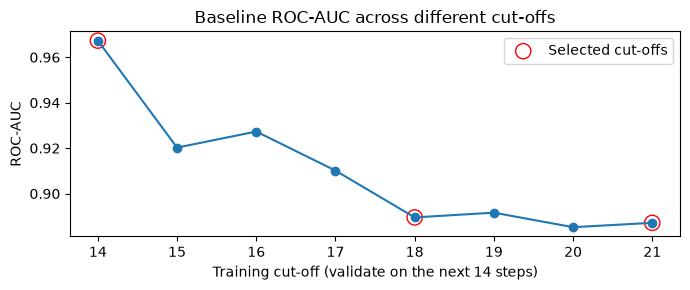

In [19]:
# 1. Check all cut-offs

# create 14-step validation windows for cut-offs 14 to 21
PRED_WINDOWS = {}

for cutoff in range(14, 22):
    PRED_WINDOWS[cutoff] = range(cutoff + 1, cutoff + 15)


# LightGBM settings used for the baseline and later models
LGBM_PARAMS = dict(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=31,
    colsample_bytree=0.5,
    subsample=0.8,
    subsample_freq=1,
    verbose=-1,
    n_jobs=8
)


# test LightGBM on all 165 raw features at each cut-off
baseline_auc = {}
baseline_predictions = {}

for cutoff in range(14, 22):
    train_rows = L[L["time_step"] <= cutoff]
    val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    seed_scores = []

    # average predictions from three seeds
    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
        model.fit(train_rows[FEATS], train_rows["label"].astype(int))
        predictions = model.predict_proba(val_rows[FEATS])[:, 1]
        seed_scores.append(predictions)

    mean_predictions = np.mean(seed_scores, axis=0)

    # store predictions so they can be reused in section 3.2
    baseline_predictions[cutoff] = mean_predictions

    baseline_auc[cutoff] = roc_auc_score(val_rows["label"], mean_predictions)

baseline_auc = pd.Series(baseline_auc)

print("Baseline ROC-AUC for each cut-off:")
print(baseline_auc.round(3).to_dict())

print("Mean ROC-AUC across all 8 cut-offs:", round(baseline_auc.mean(), 4))
print("Mean ROC-AUC for cut-offs 14, 18, 21:", round(baseline_auc[[14, 18, 21]].mean(), 4))


# plot ROC-AUC across all cut-offs
plt.figure(figsize=(7, 3))

plt.plot(baseline_auc.index, baseline_auc.values, marker="o")

# highlight the cut-offs selected for later experiments
plt.scatter([14, 18, 21], baseline_auc[[14, 18, 21]], s=120, facecolors="none", edgecolors="red", label="Selected cut-offs")

plt.xlabel("Training cut-off (validate on the next 14 steps)")
plt.ylabel("ROC-AUC")
plt.title("Baseline ROC-AUC across different cut-offs")
plt.legend()

plt.tight_layout()
plt.show()

**Comparing random K-fold and forward-chaining validation**

To check whether ignoring time affects the validation results, I compare ordinary stratified 5-fold cross-validation with the expanding window forward validation.

I use both LightGBM and an MLP to see whether the difference applies to different types of models. For random cross-validation, transactions from all 35 training time steps are mixed across the folds. For expanding window, I train only on earlier steps and validate on the next 14 steps using cut-offs 14, 18 and 21.

If random cross-validation gives much higher scores, this would suggest that it is not a reliable way to estimate performance on future transactions.

In [20]:
# 2. Random k-fold vs expanding window

# compare random 5-fold CV against expanding window
candidates = {
    "LightGBM": (
        "lgbm_raw",
        lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
    ),
    "MLP": (
        "mlp_raw",
        make_pipeline(
            SimpleImputer(strategy="median"),
            QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
            MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True, max_iter=200, random_state=0)
        )
    )
}

comparison = {}

for name, (file_name, model) in candidates.items():

    # random CV mixes transactions from all time steps
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

    random_predictions = cross_val_predict(model, L[FEATS], L["label"].astype(int), cv=cv, method="predict_proba")[:, 1]

    random_auc = roc_auc_score(L["label"], random_predictions)

    # expanding window forward val trains on earlier steps only
    forward_aucs = []

    for cutoff in [14, 18, 21]:
        train_rows = L[L["time_step"] <= cutoff]
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        seed_scores = []

        for seed in [0, 1, 2]:
            m = clone(model)

            # change the random seed for LightGBM or MLP
            if hasattr(m, "steps"):
                m.steps[-1][1].set_params(random_state=seed)
            else:
                m.set_params(random_state=seed)

            m.fit(train_rows[FEATS], train_rows["label"].astype(int))

            predictions = m.predict_proba(val_rows[FEATS])[:, 1]
            seed_scores.append(predictions)

        mean_predictions = np.mean(seed_scores, axis=0)

        forward_aucs.append(roc_auc_score(val_rows["label"], mean_predictions))

    comparison[name] = {
        "random 5-fold ROC-AUC": random_auc,
        "forward-chaining ROC-AUC": np.mean(forward_aucs)
    }

display(pd.DataFrame(comparison).T.round(4))

,random 5-fold ROC-AUC,forward-chaining ROC-AUC
LightGBM,0.9988,0.9147
MLP,0.9925,0.9379


**Takeaway**
- The difference between the two validation methods is quite large. Random 5-fold cross-validation gives ROC-AUCs of 0.999 for LightGBM and 0.993 for the MLP, compared with 0.915 and 0.938 under forward-chaining validation. This suggests that random cross-validation is too optimistic since the model can learn from transactions in the same or later time steps as the validation transactions. Since the competition requires predicting later transactions using earlier labelled data, I will use the expanding window forward validation for the remaining experiments

**Selecting the validation folds**
- I also found that nearby cut-offs have heavily overlapping validation windows, so testing every possible cut-off would repeat much of the same evaluation. I selected cut-offs 14, 18 and 21, which cover different parts of the training period. Their average baseline ROC-AUC is also close to the average across all eight cut-offs (see above). Some of the models I test later (e.g. GNN) takes a much longer time to train, so reducing the number of cut-offs reduces the computation needed while keeping the validation setup consistent across all models

    | fold | trained on steps | validated on steps |
    |---|---|---|
    | 1 | 1-14 | 15-28 |
    | 2 | 1-18 | 19-32 |
    | 3 | 1-21 | 22-35 |

In [21]:
# 3. Store validation results
# helper function to eval and store each model's predictions (ROC-AUC, PR-AUC, precision, recall and F1 for each fold + ROC-AUC separately for the large-cluster steps and the remaining steps)

# use the same three cut-offs for all later models
CUTOFFS = [14, 18, 21]

# store predictions, models and results
PREDS = {}     # model name -> validation predictions for each cut-off
MODELS = {}    # model name -> information needed to refit the model
RESULTS = {}   # model name -> metrics for each fold
SUMMARY = {}   # model name -> average metrics across the three folds

COLUMNS = ["ROC-AUC", "PR-AUC", "precision@0.5", "recall@0.5", "F1@0.5", "ROC-AUC large-cluster steps", "ROC-AUC other steps"]


def add_results(name, rank_based=False):
    # calculate the same evaluation metrics for each model
    rows = []

    for cutoff in CUTOFFS:
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        y = val_rows["label"].values.astype(int)
        p = PREDS[name][cutoff]

        # separate the large-cluster steps from the other steps
        big = val_rows["time_step"].isin(CLUSTER_STEPS).values

        row = {
            "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "ROC-AUC large-cluster steps": roc_auc_score(y[big], p[big]),
            "ROC-AUC other steps": roc_auc_score(y[~big], p[~big])
        }

        # only apply the 0.5 threshold to probability-like model scores
        # rank-based ensembles are evaluated using ranking metrics only so only use ROC-AUC and PR-AUC
        if not rank_based:
            row["precision@0.5"] = precision_score(y, p >= 0.5, zero_division=0)
            row["recall@0.5"] = recall_score(y, p >= 0.5)
            row["F1@0.5"] = f1_score(y, p >= 0.5)

        rows.append(row)

    # store metrics for each fold
    RESULTS[name] = pd.DataFrame(rows, index=["fold 1", "fold 2", "fold 3"])

    # calculate average performance across folds
    SUMMARY[name] = RESULTS[name].mean()
    s = SUMMARY[name]

    print(
        f"{name:45s} "
        f"ROC-AUC {s['ROC-AUC']:.4f} | "
        f"PR-AUC {s['PR-AUC']:.4f} | "
        f"large-cluster steps {s['ROC-AUC large-cluster steps']:.3f} | "
        f"other steps {s['ROC-AUC other steps']:.4f}"
    )

### 3.2 Baseline: LightGBM on all raw features

I use LightGBM as my baseline because gradient boosting generally works well with tabular data and does not require feature scaling. I train it using all 165 raw features, without additional feature engineering

I first evaluate its performance across the 3 expanding window forward validation folds selected in Section 3.1. I also look at the ROC-AUC for each time step in the third fold (trained on steps 1-21 and validated on steps 22-35) to see if the model is worse during certain periods, especially the large illicit clusters identified in Section 1.9

In [22]:
# use LightGBM with all 165 raw features as the baseline
BASELINE = "Baseline LightGBM (all raw features)"

# keep the model information for later experiments
MODELS[BASELINE] = ("lgbm_raw", lgb.LGBMClassifier(**LGBM_PARAMS), FEATS, [0, 1, 2])

# reuse the predictions already calculated in Section 3.1
PREDS[BASELINE] = {}

for cutoff in CUTOFFS:
    PREDS[BASELINE][cutoff] = baseline_predictions[cutoff]

# calculate and display the validation metrics
add_results(BASELINE)
display(RESULTS[BASELINE].round(4))


# look at fold 3 (trained on steps 1-21, validated on steps 22-35)
val_rows = L[L["time_step"].isin(PRED_WINDOWS[21])]

# combine the true labels and predicted scores
per_step_auc = pd.DataFrame({
    "step": val_rows["time_step"].values,
    "y": val_rows["label"].values,
    "p": PREDS[BASELINE][21]
})

# check how well the baseline performs at each time step
rows = []

for step, group in per_step_auc.groupby("step"):
    y = group["y"]
    p = group["p"]

    rows.append({
        "step": step,
        "AUC": roc_auc_score(y, p),
        "illicit": int(y.sum()),
        "illicit scored < 0.1": int(((p < 0.1) & (y == 1)).sum())
    })

# display the results for all validation steps 22-35
per_step_results = pd.DataFrame(rows).set_index("step")

with pd.option_context("display.max_columns", None):
    display(per_step_results.T.round(3))


Baseline LightGBM (all raw features)          ROC-AUC 0.9147 | PR-AUC 0.8499 | large-cluster steps 0.737 | other steps 0.9881


,ROC-AUC,PR-AUC,ROC-AUC large-cluster steps,ROC-AUC other steps,precision@0.5,recall@0.5,F1@0.5
fold 1,0.9673,0.9295,0.7521,0.9883,0.9941,0.7638,0.8639
fold 2,0.8895,0.8145,0.7230,0.9863,0.9821,0.6418,0.7763
fold 3,0.8871,0.8058,0.7364,0.9896,0.9634,0.6836,0.7997


step,22,23,24,25,26,27,28,29,30,31,32,33,34,35
AUC,0.999,0.956,0.744,1.0,0.925,1.0,1.0,0.693,0.992,0.75,0.779,0.993,0.999,0.997
illicit,158.000,53.000,137.000,118.0,96.000,24.0,85.0,329.000,83.000,106.00,342.000,23.000,37.000,182.000
illicit scored < 0.1,5.000,16.000,87.000,1.0,21.000,1.0,0.0,194.000,9.000,55.00,106.000,4.000,1.000,6.000


**Takeaway**
- The baseline performs quite well overall, with an average ROC-AUC of 0.915 and PR-AUC of 0.850 across the three validation folds. At a threshold of 0.5, precision is around 0.98, but recall is only around 0.70 => although most transactions flagged as illicit are actually illicit, the model still misses around 30% of the illicit transactions

- However, performance differs quite a lot across folds. Fold 1 achieves a ROC-AUC of 0.967, while folds 2 and 3 only reach around 0.89. These later folds include more of the large illicit-cluster steps identified in Section 1.9, which may explain why their scores are lower

- Looking at fold 3 more closely, the model performs particularly poorly on steps 24, 29, 31 and 32, with ROC-AUCs of approximately 0.74, 0.69, 0.75 and 0.78 respectively. In comparison, most other time steps achieve ROC-AUCs between 0.93 and 1.00. In step 29 alone, 194 out of 329 illicit transactions receive predicted scores below 0.1, suggesting that the model could not recognise some of these transactions well

- Across the three validation folds, ROC-AUC is only 0.737 for the large-cluster steps, compared with 0.988 for the remaining steps. This supports my earlier observation that some illicit patterns in the later training periods may differ from those the model has learned

- Overall, LightGBM provides a strong baseline using only the raw features, but its performance is much less consistent on certain time steps. Hence, I will explore whether additional graph-based features can help the model identify illicit transactions that are difficult to recognise using their individual features alone

## 4. Feature Engineering
Based on my EDA, I want to explore 3 types of additional features:
1. **Neighbour features**: Section 1.8 showed strong homophily between connected transactions, so I want to see whether the features of neighbouring transactions can help predict whether a transaction is illicit.

2. **Graph structure features**: I want to apply some of the measures covered in Lecture 8, such as degree and PageRank, to see whether a transaction's position and connections in the network provide useful information.

3. **Features using unlabelled transactions**: Since a large proportion of the training transactions are unlabelled, I want to explore whether I can still use their feature information to improve the models without needing their actual labels.

These features are created in this section and their usefulness will be compared in Section 5.

### 4.1 Directional neighbour means
First, I calculate the average feature values of each transaction's neighbours. I separate them into 2 directions:
- **Incoming neighbours**: Transactions whose outputs are spent by the current transaction

- **Outgoing neighbours**: Transactions that spend outputs created by the current transaction

I keep the 2 directions separate as they represent different relationships in the transaction graph. For each direction, I calculate the mean of all 165 features = 330 additional features in total. I only include visible neighbours, meaning labelled training transactions and test transactions. If a transaction has no visible neighbours in one direction, its corresponding neighbour means will be missing. This is to ensure that the features in train and test are consistent (Section 1.8)

In [23]:
# calculate mean feature values of incoming and outgoing neighbours
neighbour_tables = []

for M, direction in [(AT, "vin"), (A, "vout")]:

    # only include visible neighbours
    Mv = M.multiply(visible[None, :]).tocsr()

    # count the number of visible neighbours
    count = np.asarray(Mv.sum(axis=1)).ravel()

    # sum neighbour features and divide by the number of neighbours
    means = (Mv @ X0) / np.maximum(count, 1)[:, None]
    means = means.astype(np.float32)

    # set the mean to missing if there are no visible neighbours
    means[count == 0] = np.nan

    # give the features different names for incoming and outgoing neighbours
    columns = [f"{direction}_mean_{c}" for c in FEATS]

    neighbour_table = pd.DataFrame(means[gi], columns=columns, index=nodes.index)

    neighbour_tables.append(neighbour_table)


# add the neighbour features to the original transaction data
nodes = pd.concat([nodes] + neighbour_tables, axis=1)

# list of all directional neighbour features
DIR = [f"vin_mean_{c}" for c in FEATS]
DIR += [f"vout_mean_{c}" for c in FEATS]

# update labelled training and test transactions
L = nodes[(nodes["split"] == "train") & nodes["label"].notna()]
T = nodes[nodes["split"] == "test"]

print("Number of new neighbour features:", len(DIR))

Number of new neighbour features: 330


**LightGBM with directional neighbour means**

In [24]:
# compare raw features + neighbour means against the baseline
name = "LightGBM, raw + neighbour means"

# store model information for later use
MODELS[name] = ("lgbm_raw_dirall", lgb.LGBMClassifier(**LGBM_PARAMS), FEATS + DIR, [0, 1, 2])

PREDS[name] = {}

for cutoff in CUTOFFS:
    # train on earlier steps, validate on the next 14 steps
    train_rows = L[L["time_step"] <= cutoff]
    val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    seed_scores = []

    # train using 3 different seeds and average the predictions
    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
        model.fit(train_rows[FEATS + DIR], train_rows["label"].astype(int))
        predictions = model.predict_proba(val_rows[FEATS + DIR])[:, 1]
        seed_scores.append(predictions)

    PREDS[name][cutoff] = np.mean(seed_scores, axis=0)


# calculate metrics across the three validation folds
add_results(name)

# compare against the raw-feature baseline
display(pd.DataFrame(SUMMARY).T.loc[[BASELINE, name], COLUMNS].round(4))

LightGBM, raw + neighbour means               ROC-AUC 0.9071 | PR-AUC 0.8471 | large-cluster steps 0.708 | other steps 0.9872


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
Baseline LightGBM (all raw features),0.9147,0.8499,0.9799,0.6964,0.8133,0.7372,0.9881
"LightGBM, raw + neighbour means",0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872


**Takeaway**
- Adding directional neighbour means slightly reduces the average ROC-AUC from 0.915 to 0.907. However, most of this drop comes from the large illicit-cluster steps, where ROC-AUC decreases from 0.737 to 0.708

- For the other validation steps, performance remains almost the same (0.988 vs 0.987). Recall and F1 at the 0.5 threshold also improve slightly, from 0.696 to 0.710 and 0.813 to 0.823 respectively

- One possible explanation is that transactions within the large illicit clusters are connected to other transactions with similar feature patterns. Since Section 1.9 showed that these clusters differ from earlier illicit transactions, averaging their neighbours' features may not provide much additional information to help the model recognise them

- Overall, adding neighbour means does not improve the average ROC-AUC, but performance on the other validation steps remains similar to the baseline, with slightly better recall and F1. Since Section 1.10 found that the test period does not have the same long-chain patterns identified in the earlier large illicit clusters, I will keep these features for further comparison in Section 5 (Feature Selection) instead of removing them immediately

### 4.2 Network measures from Lecture 8
These features are calculated using the whole transaction graph, including unlabelled transactions and transactions without available features, since the calculations only require information about the connections between transactions.
1. **Degree**: in-degree and out-degree, source nodes (no incoming edges) and sink nodes (no outgoing edges)

2. **PageRank**: measures a node's importance based on the links it receives. I calculate it using both the original and reversed edge directions to see whether the direction of transaction flow makes a difference

3. **Path centrality**: betweenness (how often a node lies on shortest paths), closeness (how close it is to other nodes) and eigenvector centrality (how connected it is to other well-connected nodes)

4. **Cohesion**: local clustering coefficient, number of triangles and k-core number. Since Section 1.8 showed that the graph has very little local clustering, I want to see whether these measures still provide useful information => if Section 1.8 is right, these features should not help much

5. **Communities**: greedy modularity maximisation (to identify groups of more closely connected transactions). I don't use clique percolation because Section 1.8 showed there are almost no triangles, and connected components would just give back the time steps. For each transaction, I calculate its community size, community density and the proportion of its connections that stay within the same community

Since Section 1.8 showed that edges do not cross time steps, each connected component belongs to a single time step. I calculate the component-based network measures separately for each connected component.

Lastly, I check how well each feature distinguishes licit and illicit transactions on its own using ROC-AUC. This is only an initial comparison, since a feature that is weak individually may still help when combined with other features.

In [25]:
# create the full transaction graph
G = nx.DiGraph()
G.add_nodes_from(range(N))
G.add_edges_from(zip(src, dst))

# use an undirected graph for cohesion, path centrality and communities
G_und = G.to_undirected()
graph = pd.DataFrame(index=range(N))

# 1. degree
graph["g_in_deg"] = pd.Series(dict(G.in_degree()))
graph["g_out_deg"] = pd.Series(dict(G.out_degree()))
graph["g_source"] = (graph["g_in_deg"] == 0).astype(int)
graph["g_sink"] = (graph["g_out_deg"] == 0).astype(int)

# 2. pagerank
# calculate PageRank in the original and reversed directions
graph["g_pagerank"] = pd.Series(nx.pagerank(G, alpha=0.85))
graph["g_pagerank_rev"] = pd.Series(nx.pagerank(G.reverse(copy=False), alpha=0.85))

# 3. cohesion
graph["g_clustering"] = pd.Series(nx.clustering(G_und))
graph["g_triangles"] = pd.Series(nx.triangles(G_und))
graph["g_core"] = pd.Series(nx.core_number(G_und))

# create empty columns for path centrality and communities
columns = ["g_betweenness", "g_closeness", "g_eigen", "community", "g_comm_size", "g_comm_density", "g_comm_inside_share"]

for col in columns:
    graph[col] = np.nan

# 4. path centrality and communities
# each connected component belongs to one time step, a time step can contain more than one component
community_id = 0

for c in range(n_components):
    members = np.where(COMPONENT == c)[0]

    # undirected graph containing only nodes in this component
    step_graph = G_und.subgraph(members).copy()

    # betweenness: how often a node lies on shortest paths
    betweenness = nx.betweenness_centrality(step_graph)
    graph.loc[members, "g_betweenness"] = pd.Series(betweenness)

    # closeness: how close a node is to other nodes
    closeness = nx.closeness_centrality(step_graph)
    graph.loc[members, "g_closeness"] = pd.Series(closeness)

    # eigenvector centrality: importance of connected neighbours
    eigen = nx.eigenvector_centrality(step_graph, max_iter=1000)
    graph.loc[members, "g_eigen"] = (pd.Series(eigen) * np.sqrt(len(members)))

    # 5. find communities using greedy modularity maximisation
    communities = nx.community.greedy_modularity_communities(step_graph)

    for group in communities:
        group = list(group)

        # graph containing only transactions in this community
        community_graph = step_graph.subgraph(group)

        # number of edges each node has inside the community
        inside = pd.Series(dict(community_graph.degree()))

        # total number of edges of each node in the component
        total = pd.Series(dict(step_graph.degree(group)))

        # assign community features to each transaction
        graph.loc[group, "community"] = community_id
        graph.loc[group, "g_comm_size"] = len(group)
        graph.loc[group, "g_comm_density"] = nx.density(community_graph)
        graph.loc[group, "g_comm_inside_share"] = (inside / total.clip(lower=1))

        community_id += 1


# group the network measures
GRAPH_GROUPS = {
    "degree group": ["g_in_deg", "g_out_deg", "g_source", "g_sink"],
    "structural PageRank": ["g_pagerank", "g_pagerank_rev"],
    "path centrality": ["g_betweenness", "g_closeness", "g_eigen"],
    "cohesion": ["g_clustering", "g_triangles", "g_core"],
    "communities": ["g_comm_size", "g_comm_density", "g_comm_inside_share"]
}

# add graph features to the transaction data
for cols in GRAPH_GROUPS.values():
    for col in cols:
        nodes[col] = graph[col].values[gi]

# keep community IDs for Section 7
COMMUNITY = graph["community"].values.astype(np.int64)

# update labelled training and test data
L = nodes[(nodes["split"] == "train") & nodes["label"].notna()]
T = nodes[nodes["split"] == "test"]

# check how well each graph feature separates licit and illicit transactions
single = {}

for group, cols in GRAPH_GROUPS.items():
    for col in cols:
        single[(group, col)] = roc_auc_score(L["label"].astype(int), L[col])

single_results = pd.Series(single).to_frame("AUC on its own")

display(single_results.round(3).T)

degree group                           structural PageRank  \
                   g_in_deg g_out_deg g_source g_sink          g_pagerank   
AUC on its own        0.458     0.417    0.469  0.523               0.495   

                              path centrality                      \
               g_pagerank_rev   g_betweenness g_closeness g_eigen   
AUC on its own          0.383           0.427       0.378   0.452   

                   cohesion                    communities                 \
               g_clustering g_triangles g_core g_comm_size g_comm_density   
AUC on its own        0.484       0.484  0.407       0.387          0.608   

                                    
               g_comm_inside_share  
AUC on its own               0.551

**Takeaway**
- Most network measures have ROC-AUCs relatively close to 0.5, suggesting that they are not particularly strong at distinguishing illicit and licit transactions on their own compared with the raw features. However, an ROC-AUC below 0.5 does not necessarily mean a feature is useless, as it may indicate that illicit transactions tend to have lower values for that feature. For example, illicit transactions tend to have lower reversed PageRank (AUC 0.38), closeness (0.38) and out-degree (0.42). This suggests that illicit transactions generally have fewer outgoing connections and occupy different positions in the network compared with licit transactions

- I also look at community size and density to see whether illicit transactions tend to belong to communities with different structures. These features may capture information about the groups of transactions they belong to, instead of just their individual connections. Clustering coefficient and triangle count have ROC-AUCs close to 0.5 (around 0.48), suggesting that they do not distinguish the two classes well on their own => consistent with Section 1.8, where I found very little local clustering

- Overall, although the network measures are relatively weak individually, they may still provide additional information when combined with the raw transaction features. I will test this further in Section 5

### 4.3 Learning from the unlabelled transactions with PCA
Section 1.7 showed that labelled and unlabelled transactions have different feature distributions, so I decided not to assign labels to the unlabelled transactions at this stage. However, I can still use their features without needing their actual labels. I use Principal Component Analysis (PCA) to reduce the 165 original features into 10 new features that capture the main directions of variation in the data.

Before applying PCA, I use a quantile transformation because Section 1.4 showed that many features are highly skewed. I fit PCA using both labelled and unlabelled transactions from the training period, allowing it to learn from more data.

To avoid data leakage, I follow the forward-chaining validation approach from Section 3.1. For each fold, the quantile transformer and PCA are fitted only on transactions up to the training cut-off. For the final model, they are fitted on steps 1-35.

Lastly, I check how well each PCA feature distinguishes licit and illicit transactions on its own using ROC-AUC, with PCA fitted on steps 1-35. I will test whether adding these features improves model performance in Section 5.

In [26]:
# fit PCA using only the transactions available before each cut-off
feature_rows = nodes[nodes["split"].isin(["train", "test"])]

PCA_COLS = [f"pca_{i}" for i in range(10)]
PCA_FEATURES = {}

for cutoff in CUTOFFS + [35]:
    fit_rows = feature_rows[feature_rows["time_step"] <= cutoff]

    # use quantile transformation first because many features are skewed
    quantile = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)
    scaled = quantile.fit_transform(fit_rows[FEATS])

    # fit PCA on the training period, including unlabelled transactions
    pca = PCA(n_components=10, random_state=0)
    pca.fit(scaled)

    # apply the same transformation to the other transactions
    all_scaled = quantile.transform(feature_rows[FEATS])
    components = pca.transform(all_scaled)

    PCA_FEATURES[cutoff] = pd.DataFrame(components, columns=PCA_COLS, index=feature_rows.index)

    if cutoff == 35:
        explained = pca.explained_variance_ratio_


print("Variance explained by each component:", explained.round(3))
print("Total variance explained:", round(explained.sum(), 3))

# check whether the PCA features can separate illicit and licit transactions
single_pca = {}

for col in PCA_COLS:
    single_pca[col] = roc_auc_score(L["label"].astype(int), PCA_FEATURES[35].loc[L.index, col])

display(pd.Series(single_pca).to_frame("AUC on its own").round(3).T)

Variance explained by each component: [0.176 0.13  0.097 0.079 0.064 0.047 0.031 0.029 0.027 0.024]
Total variance explained: 0.705


,pca_0,pca_1,pca_2,pca_3,pca_4,pca_5,pca_6,pca_7,pca_8,pca_9
AUC on its own,0.368,0.306,0.151,0.472,0.382,0.783,0.749,0.48,0.639,0.732


Section 1.10 showed a noticeable distribution shift around step 43. Since PCA combines information from the original features, I want to see whether its components are less affected by these changes.

I use the same period classification approach as Section 1.10, where a classifier tries to distinguish transactions from two different periods without using fraud labels. An ROC-AUC closer to 0.5 means the periods are harder to distinguish.

I compare 2 ordinary training periods (22-28 against 29-35) and two test periods (36-42 against 43-49), using the PCA components and raw features separately. All PCA components are calculated using the PCA fitted on steps 1-35 in Section 4.3.

In [27]:
# use PCA fitted on steps 1-35 for both training and test periods
visible_rows = nodes[nodes["visible"]].copy()
visible_rows[PCA_COLS] = PCA_FEATURES[35].loc[visible_rows.index]

period_pairs = {
    "ordinary, 22-28 vs 29-35": ((22, 28), (29, 35)),
    "test, 36-42 vs 43-49": ((36, 42), (43, 49))
}

input_sets = {
    "10 PCA components": PCA_COLS,
    "20 strongest features": list(strongest.index[:20]),
    "all 165 features": FEATS
}

change = {}

for period, (first_steps, second_steps) in period_pairs.items():
    a = visible_rows[visible_rows["time_step"].between(*first_steps)]
    b = visible_rows[visible_rows["time_step"].between(*second_steps)]

    for inputs, cols in input_sets.items():
        X = pd.concat([a[cols], b[cols]])
        y = np.r_[np.zeros(len(a)), np.ones(len(b))]

        model = lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=0)
        cv = StratifiedKFold(5, shuffle=True, random_state=0)
        predictions = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
        change[(period, inputs)] = roc_auc_score(y, predictions)

pd.Series(change).unstack().round(3)

,10 PCA components,20 strongest features,all 165 features
"ordinary, 22-28 vs 29-35",0.777,0.926,1.0
"test, 36-42 vs 43-49",0.739,0.902,1.0


**Takeaway**
- The PCA components make the two periods harder to distinguish than the raw features. For the ordinary training periods, the ROC-AUC is 0.78 using PCA, compared with 0.93 using the 20 strongest raw features and almost 1.00 using all 165 features. Across step 43, the results are similar => 0.74 for PCA, 0.90 for the 20 strongest features and almost 1.00 for all raw features => PCA captures fewer of the differences between periods. However, PCA also reduces 165 features to just 10, so part of the difference could just be due to having less information available

Hence, I cannot conclude that PCA is necessarily more stable or better for fraud detection. In Section 5, I test whether adding PCA actually improves the validation ROC-AUC. I will keep it as a possible alternative representation to explore in later experiments.

## 5. Feature Selection
I use the EDA and validation results to decide which features to keep. Rather than testing every possible combination, I use the raw features and neighbour means as the baseline, then test whether each additional feature group provides useful information beyond them.
1. **Raw features**: I keep all 165 features. Section 1.5 showed that 147 features have significantly different distributions between licit and illicit transactions. Even features that are not strong individually might still be useful when combined with others.

2. **Correlated features**: Section 1.6 found several highly correlated features. I decided to keep them for now because LightGBM can handle correlated inputs, while the logistic regression model uses regularisation.

3. **Neighbour means**: I already tested these in Section 4.1. Although they slightly reduced ROC-AUC, I will keep trying them because Section 1.8 showed strong homophily in the transaction graph.

4. **Network measures and PCA**: I have not tested these groups in a supervised model yet. I add each network feature group separately to LightGBM, alongside the raw features and neighbour means, to see whether it provides additional information. I also test the PCA components from Section 4.3, fitting PCA separately for each validation cut-off.

I use the same 3 folds and LightGBM settings as Section 3 so that the results are comparable.

In [28]:
BASE_FEATS = FEATS + DIR
fs_names = []

# test each group of network features separately
for group, cols in GRAPH_GROUPS.items():
    name = f"LightGBM, raw + neighbour means + {group}"
    use = BASE_FEATS + cols

    MODELS[name] = (group, lgb.LGBMClassifier(**LGBM_PARAMS), use, [0, 1, 2])

    PREDS[name] = {}

    for cutoff in CUTOFFS:
        train_rows = L[L["time_step"] <= cutoff]
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        seed_scores = []
        for seed in [0, 1, 2]:
            model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
            model.fit(train_rows[use], train_rows["label"].astype(int))
            seed_scores.append(model.predict_proba(val_rows[use])[:, 1])

        PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

    add_results(name)
    fs_names.append(name)


# test PCA, using the PCA fitted for each cut-off in Section 4.3
name = "LightGBM, raw + neighbour means + PCA components"
PREDS[name] = {}

for cutoff in CUTOFFS:
    train_rows = L[L["time_step"] <= cutoff]
    val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    X_train = pd.concat([train_rows[BASE_FEATS], PCA_FEATURES[cutoff].loc[train_rows.index]], axis=1)
    X_val = pd.concat([val_rows[BASE_FEATS], PCA_FEATURES[cutoff].loc[val_rows.index]], axis=1)

    seed_scores = []
    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
        model.fit(X_train, train_rows["label"].astype(int))
        seed_scores.append(model.predict_proba(X_val)[:, 1])

    PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

add_results(name)
fs_names.append(name)

# compare the results with the raw + neighbour features
display(pd.DataFrame(SUMMARY).T.loc[["LightGBM, raw + neighbour means"] + fs_names, COLUMNS].round(4))

LightGBM, raw + neighbour means + degree group ROC-AUC 0.9053 | PR-AUC 0.8467 | large-cluster steps 0.698 | other steps 0.9872
LightGBM, raw + neighbour means + structural PageRank ROC-AUC 0.9001 | PR-AUC 0.8447 | large-cluster steps 0.695 | other steps 0.9869
LightGBM, raw + neighbour means + path centrality ROC-AUC 0.9027 | PR-AUC 0.8454 | large-cluster steps 0.697 | other steps 0.9871
LightGBM, raw + neighbour means + cohesion    ROC-AUC 0.8994 | PR-AUC 0.8447 | large-cluster steps 0.686 | other steps 0.9870
LightGBM, raw + neighbour means + communities ROC-AUC 0.9007 | PR-AUC 0.8444 | large-cluster steps 0.693 | other steps 0.9868
LightGBM, raw + neighbour means + PCA components ROC-AUC 0.9060 | PR-AUC 0.8468 | large-cluster steps 0.709 | other steps 0.9871


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
"LightGBM, raw + neighbour means",0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, raw + neighbour means + degree group",0.9053,0.8467,0.9839,0.7056,0.8207,0.6981,0.9872
"LightGBM, raw + neighbour means + structural PageRank",0.9001,0.8447,0.9834,0.7069,0.8214,0.6947,0.9869
"LightGBM, raw + neighbour means + path centrality",0.9027,0.8454,0.9828,0.7067,0.8210,0.6965,0.9871
"LightGBM, raw + neighbour means + cohesion",0.8994,0.8447,0.9826,0.7066,0.8210,0.6860,0.9870
"LightGBM, raw + neighbour means + communities",0.9007,0.8444,0.9834,0.7087,0.8225,0.6925,0.9868
"LightGBM, raw + neighbour means + PCA components",0.9060,0.8468,0.9829,0.7099,0.8231,0.7092,0.9871


**Takeaway**
- None of the network feature groups improve the model. Adding them lowers the average ROC-AUC from 0.907 to between 0.899 and 0.905, mostly because of the large-cluster steps, and none of them help on the other steps either (0.9868 to 0.9872 vs 0.9872). Their individual AUCs were also weak in Section 4.2, and the competition mentions that the actual number of inputs and outputs of a transaction is captured separately among its local features, so some of what these measures describe may already be included. Hence, I leave the network measures out

- When PCA is fitted separately for each fold using only the steps up to its cut-off, adding the PCA components makes almost no difference (0.906 vs 0.907, and 0.9871 vs 0.9872 on the other steps). Hence, I leave PCA out of the main feature set, but I test it again in Section 7.3, since it is the only part that directly uses the feature values of the unlabelled training transactions

- I keep the neighbour means. Section 4.1 showed that their cost is mostly on the large-cluster steps, Section 1.8 showed strong homophily, and Section 1.10 showed that the graph structure changes less than the features in the test period. Hence, I expect neighbour information to be more useful in the test period than in validation

- Overall, my final feature set (`SELECTED`) contains the 165 raw features and the 330 neighbour means, so 495 features in total

In [29]:
# final feature set = raw features + directional neighbour means
SELECTED = FEATS + DIR

print("Selected features:", len(SELECTED))
print("Raw features:", len(FEATS))
print("Neighbour means:", len(DIR))

Selected features: 495
Raw features: 165
Neighbour means: 330


## 6. Model Exploration
### 6.1 Comparing model families
Next, I compare different types of models to see which one works best with the selected features. Each family makes different assumptions about the data:
1. **Logistic regression**: a linear model, which shows how far a simple decision boundary can go

2. **Decision tree**: a single tree, which is easy to interpret but can overfit

3. **Random forest**: bagged trees, which average many trees trained on random samples of the data

4. **XGBoost and LightGBM**: boosted trees, which build trees one after another to correct the earlier mistakes

5. **MLP**: a neural network, which can learn non-linear combinations of the features

All models use the same `SELECTED` features and the same 3 folds. As explained in Section 2, logistic regression and the MLP use median imputation and a quantile transformation inside their pipelines, while the tree-based models use the features directly.

In [30]:
# models to compare: name -> (model, seeds)
experiments = {
    "Logistic regression": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
            LogisticRegression(C=0.05, max_iter=3000)
        ),
        [0]
    ),
    "Decision tree": (
        DecisionTreeClassifier(max_depth=8, min_samples_leaf=20),
        [0, 1, 2]
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=300, max_features=0.2, min_samples_leaf=2, n_jobs=8),
        [0]
    ),
    "XGBoost": (
        xgb.XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.5, n_jobs=8),
        [0, 1, 2]
    ),
    "MLP": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
            MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True, max_iter=200)
        ),
        [0, 1, 2]
    ),
    "LightGBM": (
        lgb.LGBMClassifier(**LGBM_PARAMS),
        [0, 1, 2]
    )
}

for name, (model, seeds) in experiments.items():
    PREDS[name] = {}

    for cutoff in CUTOFFS:
        train_rows = L[L["time_step"] <= cutoff]
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        seed_scores = []

        for seed in seeds:
            m = clone(model)

            # in a pipeline, only the final classifier gets the seed
            if hasattr(m, "steps"):
                m.steps[-1][1].set_params(random_state=seed)
            else:
                m.set_params(random_state=seed)

            m.fit(train_rows[SELECTED], train_rows["label"].astype(int))
            predictions = m.predict_proba(val_rows[SELECTED])[:, 1]
            seed_scores.append(predictions)

        PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

    add_results(name)


# compare the model families
family_results = pd.DataFrame(SUMMARY).T.loc[list(experiments), COLUMNS]
display(family_results.sort_values("ROC-AUC", ascending=False).round(4))

Logistic regression                           ROC-AUC 0.8676 | PR-AUC 0.8094 | large-cluster steps 0.688 | other steps 0.9723
Decision tree                                 ROC-AUC 0.8756 | PR-AUC 0.7474 | large-cluster steps 0.703 | other steps 0.9513
Random forest                                 ROC-AUC 0.8631 | PR-AUC 0.8274 | large-cluster steps 0.608 | other steps 0.9765
XGBoost                                       ROC-AUC 0.8728 | PR-AUC 0.8365 | large-cluster steps 0.619 | other steps 0.9842
MLP                                           ROC-AUC 0.8614 | PR-AUC 0.8273 | large-cluster steps 0.631 | other steps 0.9777
LightGBM                                      ROC-AUC 0.9071 | PR-AUC 0.8471 | large-cluster steps 0.708 | other steps 0.9872


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
Decision tree,0.8756,0.7474,0.8487,0.5896,0.6846,0.7029,0.9513
XGBoost,0.8728,0.8365,0.9776,0.7155,0.8248,0.6194,0.9842
Logistic regression,0.8676,0.8094,0.8835,0.7096,0.7858,0.6877,0.9723
Random forest,0.8631,0.8274,0.9823,0.6978,0.8146,0.6078,0.9765
MLP,0.8614,0.8273,0.9613,0.7105,0.8160,0.6313,0.9777


**Takeaway**
- LightGBM is clearly the best model family with these features, with an average ROC-AUC of 0.907 and PR-AUC of 0.847. It is also the best on the other validation steps (0.987). The other families are all between 0.861 and 0.876

- The MLP drops a lot compared with the raw features alone (0.861 here vs 0.938 in Section 3.1). One possible reason is that the 330 neighbour means contain many missing values, which are filled in with the median. This may add a lot of noise for a neural network trained on only around 31,000 labelled transactions, while tree-based models can handle missing values directly. However, I don't go back to the MLP on the raw features either. When I tested an MLP on the public leaderboard, it scored 0.916, which is lower than the competition baseline, so its higher validation score in Section 3.1 did not carry over to the test period

- XGBoost, random forest and the MLP perform especially poorly on the large-cluster steps (0.61 to 0.63), while the single decision tree and logistic regression are the weakest on the other steps (0.951 and 0.972). This suggests that the relationship between the features and the label is non-linear and needs more than one tree to capture

- At the 0.5 threshold, LightGBM, random forest and XGBoost have the highest precision (around 0.98), while XGBoost has the highest recall among the families (0.72)

- Overall, I will use LightGBM for the rest of the experiments

### 6.2 Handling class imbalance
Section 1.3 showed that the classes are imbalanced, with around 1 illicit transaction for every 7.6 licit ones. I try 3 common ways of handling this with LightGBM:
1. **Class weights**: each illicit transaction gets a weight of #licit / #illicit (calculated on each fold's own training rows), so mistakes on illicit transactions count more during training. This mainly pushes the predicted probabilities upwards, so I expect it to improve recall at the 0.5 threshold. However, ROC-AUC only depends on how the transactions are ranked, so it may not improve ROC-AUC

2. **Random undersampling**: keeps all illicit transactions and randomly drops licit ones until both classes have the same number of transactions. This throws away most of the licit transactions, so the model sees less of what normal transactions look like

3. **SMOTE**: creates synthetic illicit transactions by interpolating between an illicit transaction and one of its 5 nearest illicit neighbours. SMOTE cannot handle missing values, so missing neighbour means are filled with the median of the training fold first

The resampling is only applied to the training rows of each fold, never to the validation rows. Since the synthetic transactions do not exist in the graph, SMOTE cannot be used for the graph part of collective classification, only for its second stage, which is just a table of features (Section 7.3)

In [31]:
# 1. class weights
name = "LightGBM, class-weighted"
PREDS[name] = {}

for cutoff in CUTOFFS:
    train_rows = L[L["time_step"] <= cutoff]
    val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    y = train_rows["label"].astype(int)

    # number of licit transactions for each illicit transaction
    weight = (y == 0).sum() / (y == 1).sum()

    seed_scores = []

    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, scale_pos_weight=weight, random_state=seed)
        model.fit(train_rows[SELECTED], y)
        predictions = model.predict_proba(val_rows[SELECTED])[:, 1]
        seed_scores.append(predictions)

    PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

add_results(name)

display(pd.DataFrame(SUMMARY).T.loc[["LightGBM", name], COLUMNS].round(4))

LightGBM, class-weighted                      ROC-AUC 0.8850 | PR-AUC 0.8388 | large-cluster steps 0.656 | other steps 0.9851


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, class-weighted",0.8850,0.8388,0.9651,0.7202,0.8239,0.6564,0.9851


**Takeaway**
- Class weights work as expected at the 0.5 threshold => recall increases from 0.710 to 0.720 and precision decreases from 0.984 to 0.965, so F1 barely changes (0.823 to 0.824)

- However, the ranking gets worse, with ROC-AUC dropping from 0.907 to 0.885, mostly on the large-cluster steps (0.708 to 0.656). Re-weighting mainly pushes the predicted probabilities towards the illicit class rather than separating the two classes better, so I don't use class weights for a ranking metric like ROC-AUC

Next, I try random undersampling and SMOTE, using the same folds and LightGBM settings.

In [32]:
# 2. random undersampling and SMOTE
RESAMPLERS = ["LightGBM, random undersampling", "LightGBM, SMOTE"]

for name in RESAMPLERS:
    PREDS[name] = {}

    for cutoff in CUTOFFS:
        train_rows = L[L["time_step"] <= cutoff]
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        X_train = train_rows[SELECTED]
        X_val = val_rows[SELECTED]
        y = train_rows["label"].astype(int)

        # SMOTE can't handle missing values, so fill the missing neighbour means with the median of the training fold
        if name == "LightGBM, SMOTE":
            imputer = SimpleImputer(strategy="median")
            imputer.fit(X_train)

            X_train = pd.DataFrame(imputer.transform(X_train), columns=SELECTED)
            X_val = pd.DataFrame(imputer.transform(X_val), columns=SELECTED)

        seed_scores = []

        for seed in [0, 1, 2]:
            # resample the training rows to a 1 to 1 class ratio
            if name == "LightGBM, SMOTE":
                X_resampled, y_resampled = SMOTE(random_state=seed).fit_resample(X_train, y)
            else:
                X_resampled, y_resampled = RandomUnderSampler(random_state=seed).fit_resample(X_train, y)

            model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
            model.fit(X_resampled, y_resampled)
            predictions = model.predict_proba(X_val)[:, 1]
            seed_scores.append(predictions)

        PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

    add_results(name)


# compare all the ways of handling the class imbalance
imbalance_names = ["LightGBM", "LightGBM, class-weighted"] + RESAMPLERS
display(pd.DataFrame(SUMMARY).T.loc[imbalance_names, COLUMNS].round(4))

LightGBM, random undersampling                ROC-AUC 0.9018 | PR-AUC 0.8429 | large-cluster steps 0.685 | other steps 0.9861
LightGBM, SMOTE                               ROC-AUC 0.9093 | PR-AUC 0.8468 | large-cluster steps 0.715 | other steps 0.9867


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, class-weighted",0.8850,0.8388,0.9651,0.7202,0.8239,0.6564,0.9851
"LightGBM, random undersampling",0.9018,0.8429,0.7731,0.7817,0.7751,0.6854,0.9861
"LightGBM, SMOTE",0.9093,0.8468,0.9675,0.7215,0.8252,0.7153,0.9867


**Takeaway**
- Random undersampling makes the ranking worse => ROC-AUC drops from 0.907 to 0.902, mostly on the large-cluster steps (0.708 to 0.685), and the other steps also drop slightly (0.9872 to 0.9861). At the 0.5 threshold it flags many more transactions, so recall increases a lot (0.710 to 0.782) but precision drops from 0.984 to 0.773. Since there are around 7.6 licit transactions for every illicit one, balancing the classes means dropping around 87% of the licit transactions. Hence, the model sees fewer examples of what normal transactions look like, so it is more likely to score unusual licit transactions as suspicious. The large drop in precision is also because the model is trained on a 50/50 split, so it overestimates how common illicit transactions are and gives higher scores overall

- SMOTE is the only method that does not hurt the ranking => it is about the same on the other steps (0.9867 vs 0.9872, which is a very small difference), slightly better on the large-cluster steps (0.715 vs 0.708), and it increases recall at 0.5 slightly (0.710 to 0.722) while keeping precision high (0.968). However, part of this difference could come from filling the missing values with the median rather than from the synthetic transactions themselves

- Overall, I will use SMOTE in my final models in Section 7.3. Since the synthetic transactions do not exist in the graph, SMOTE can only be applied to the second stage of collective classification. For the rest of Sections 6 and 7, I keep the original class ratio so that the results stay comparable with the baseline

## 7. Graph Models and Ensembles
### 7.1 Graph neural network (directional GraphSAGE)
The neighbour means in Section 4.1 are fixed summaries of a transaction's neighbours. A graph neural network (GNN) instead learns which neighbour information is useful. I use a directional version of GraphSAGE:
1. **Message passing**: each layer combines a transaction's own representation with the average of its visible incoming neighbours and the average of its visible outgoing neighbours, keeping the 2 directions separate like in Section 4.1

2. **Training**: only the labelled training transactions are used in the loss, but all visible transactions pass information to their neighbours

3. **Inputs**: since the GNN does its own neighbour averaging, I only give it the 165 raw features, converted to ranks and then to a normal distribution so that extreme values do not dominate. The ranks are calculated using all available transactions, including the validation and test periods, so this uses future feature distributions. However, no labels are used in this transformation

PyTorch needs the model to be written as a class.

In [33]:
# create sparse matrices for averaging over visible neighbours (indexed by the rows of nodes)
n_rows = len(nodes)
row_of = pd.Series(nodes.index.values, index=nodes["txId"].values)

node_edges = pd.DataFrame({
    "a": edges["txId1"].map(row_of),
    "b": edges["txId2"].map(row_of)
})
node_edges = node_edges.dropna().astype(int)

A_rows = sp.csr_matrix(
    (np.ones(len(node_edges), np.float32), (node_edges["a"], node_edges["b"])),
    shape=(n_rows, n_rows)
)
A_rows.data[:] = 1

visible_rows = nodes["visible"].values.astype(np.float32)

operators = []

# incoming neighbours first, then outgoing neighbours
for matrix in [A_rows.T.tocsr(), A_rows]:

    # only average over visible neighbours
    matrix = matrix.multiply(visible_rows[None, :]).tocsr()
    counts = np.asarray(matrix.sum(axis=1)).ravel()
    matrix = (sp.diags(1 / np.maximum(counts, 1)) @ matrix).tocoo()

    # convert to a sparse PyTorch matrix
    indices = np.vstack([matrix.row, matrix.col]).astype(np.int64)
    values = matrix.data.astype(np.float32)
    operators.append(torch.sparse_coo_tensor(indices, values, matrix.shape).coalesce())

G_IN, G_OUT = operators


# convert the raw features to ranks and then to a normal distribution
GNN_INPUT = FEATS
ranks = nodes[GNN_INPUT].rank(pct=True).fillna(0.5).values
ranks = np.clip(ranks, 1e-4, 1 - 1e-4)
X_GNN = torch.tensor(stats.norm.ppf(ranks).astype(np.float32))


# directional GraphSAGE model
class DirSAGE(nn.Module):
    def __init__(self, d_in, hidden=64, layers=2, dropout=0.3):
        super().__init__()
        sizes = [d_in] + [hidden] * layers
        self.lins = nn.ModuleList([nn.Linear(sizes[i] * 3, sizes[i + 1]) for i in range(layers)])
        self.out = nn.Linear(hidden, 1)
        self.dropout = dropout

    def forward(self, x):
        for lin in self.lins:
            # combine own features, mean of incoming neighbours and mean of outgoing neighbours
            x = torch.cat([x, torch.sparse.mm(G_IN, x), torch.sparse.mm(G_OUT, x)], dim=1)
            x = F.dropout(F.relu(lin(x)), self.dropout, self.training)
        return self.out(x).squeeze(-1)

/var/folders/dt/5cbk9kp92zggglf749y05y8c0000gn/T/ipykernel_17001/2728980416.py:32: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  operators.append(torch.sparse_coo_tensor(indices, values, matrix.shape).coalesce())


In [34]:
# train the GNN on all labelled steps up to each cut-off
name = "GNN (directional GraphSAGE)"
PREDS[name] = {}

for cutoff in CUTOFFS:
    train_rows = L[L["time_step"] <= cutoff]
    val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    torch.manual_seed(0)
    model = DirSAGE(X_GNN.shape[1])
    optimiser = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)

    idx = torch.tensor(train_rows.index.values)
    y = torch.tensor(train_rows["label"].values.astype(np.float32))

    # full-batch training for 300 epochs
    for epoch in range(300):
        model.train()
        optimiser.zero_grad()
        loss = F.binary_cross_entropy_with_logits(model(X_GNN)[idx], y)
        loss.backward()
        optimiser.step()

    # scores for every transaction, then keep the validation transactions
    model.eval()
    with torch.no_grad():
        scores = torch.sigmoid(model(X_GNN)).numpy()

    PREDS[name][cutoff] = scores[val_rows.index.values]

add_results(name)

GNN (directional GraphSAGE)                   ROC-AUC 0.8710 | PR-AUC 0.8346 | large-cluster steps 0.660 | other steps 0.9811


**Takeaway**
- The GNN performs clearly worse than LightGBM, with an average ROC-AUC of 0.871 and PR-AUC of 0.835. It is worse on both the large-cluster steps (0.660) and the other steps (0.981)

- It has the highest recall at 0.5 of all the models (0.750), but mainly because it flags more transactions, which lowers its precision (0.942) (see results below after 7.2)

- One possible reason is that learning everything through the neighbours from scratch is difficult with only around 31,000 labelled transactions. On the large-cluster steps, it also has the same problem as the neighbour means in Section 4.1, since the neighbours of these transactions are part of the same new clusters

### 7.2 Collective classification (CC)
Section 1.8 showed that the labels of neighbouring transactions are informative (homophily), but the labels of the test transactions are unknown. Collective classification (CC) gets around this by using the neighbours' predicted scores instead of their labels. It works in 2 stages, so it is also a kind of stacked ensemble, since the predictions of one model become the inputs of another:
1. **First stage**: a LightGBM using the `SELECTED` features scores every visible transaction. For the training transactions, the scores are out-of-fold. I split the training steps into 5 blocks of consecutive steps and score each block using a model trained on the other 4 blocks, so a transaction's own label is never used to score it. Otherwise, the neighbour features would leak the labels

2. **Second stage**: another LightGBM uses the `SELECTED` features plus summaries of the neighbours' first-stage scores, which are the mean and max score of the incoming, outgoing and all neighbours, and the average score 2 hops away

The validation and test transactions (and all their neighbours) are scored by a first stage trained only on the steps up to the cut-off, so no information from after the cut-off leaks in. Since Section 1.8 showed that edges never cross time steps, holding out whole steps means that a held-out transaction's neighbours are always held out too. I also include cut-off 35 here, which is the refit on all labelled steps that Section 10 uses for the test predictions.

One limitation is that the out-of-fold scores for earlier training blocks come from models that have seen later training steps. Hence, these scores may behave differently from validation and test scores, where the first-stage model only uses transactions up to the training cut-off. This could affect how much the second stage learns to rely on neighbour scores.

In [35]:
# 1. first stage, a score for every visible transaction
FIRST = {}

for cutoff in CUTOFFS + [35]:
    train_rows = L[L["time_step"] <= cutoff]
    other_rows = nodes[nodes["visible"] & ~nodes.index.isin(train_rows.index)]

    first = pd.Series(np.nan, index=nodes.index)

    # out-of-fold scores for the training transactions, using 5 blocks of whole steps
    blocks = np.array_split(np.array(sorted(train_rows["time_step"].unique())), 5)

    for block in blocks:
        fit_part = train_rows[~train_rows["time_step"].isin(block)]
        held_out = train_rows[train_rows["time_step"].isin(block)]

        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
        model.fit(fit_part[SELECTED], fit_part["label"].astype(int))
        first[held_out.index] = model.predict_proba(held_out[SELECTED])[:, 1]

    # scores for the validation and test transactions, using all the training steps
    model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
    model.fit(train_rows[SELECTED], train_rows["label"].astype(int))
    first[other_rows.index] = model.predict_proba(other_rows[SELECTED])[:, 1]

    FIRST[cutoff] = first


# 2. summaries of the neighbours' first-stage scores
SCORE_FEATURES = {}

for cutoff in CUTOFFS + [35]:
    # first-stage scores in graph order (unlabelled training transactions have no score)
    P = np.zeros(N, np.float32)
    has_score = np.zeros(N, np.float32)

    ok = FIRST[cutoff].notna().values
    P[gi[ok]] = FIRST[cutoff].values[ok]
    has_score[gi[ok]] = 1

    score_features = {}

    for M, direction in [(AT, "in"), (A, "out"), (U, "all")]:
        # only neighbours that have a score count
        Mm = M.multiply(has_score[None, :]).tocsr()
        count = np.asarray(Mm.sum(axis=1)).ravel()

        mean = (Mm @ P) / np.maximum(count, 1)
        mx = np.asarray(Mm.multiply(P[None, :]).max(axis=1).todense()).ravel()

        mean[count == 0] = np.nan
        mx[count == 0] = np.nan

        score_features[f"sp_{direction}_mean"] = mean[gi]
        score_features[f"sp_{direction}_max"] = mx[gi]

    # average score 2 hops away
    scored = U.multiply(has_score[None, :]).tocsr()
    R = sp.diags(1 / np.maximum(np.asarray(scored.sum(axis=1)).ravel(), 1)) @ scored
    score_features["sp_2hop_mean"] = (R @ (R @ P))[gi]

    SCORE_FEATURES[cutoff] = pd.DataFrame(score_features, index=nodes.index)

BASIC_SCORES = list(SCORE_FEATURES[35].columns)


# 3. second stage, using the selected features and the neighbour-score features
TEST_PREDS = {}

name = "Collective classification"
PREDS[name] = {}

for cutoff in CUTOFFS + [35]:
    train_rows = L[L["time_step"] <= cutoff]

    # cut-off 35 predicts the test set, the other cut-offs predict their validation steps
    if cutoff == 35:
        targets = T
    else:
        targets = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    X_train = pd.concat([train_rows[SELECTED], SCORE_FEATURES[cutoff].loc[train_rows.index]], axis=1)
    X_target = pd.concat([targets[SELECTED], SCORE_FEATURES[cutoff].loc[targets.index]], axis=1)

    seed_scores = []

    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
        model.fit(X_train, train_rows["label"].astype(int))
        seed_scores.append(model.predict_proba(X_target)[:, 1])

    if cutoff == 35:
        TEST_PREDS[name] = np.mean(seed_scores, axis=0)
    else:
        PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

add_results(name)

display(pd.DataFrame(SUMMARY).T.loc[["LightGBM", "GNN (directional GraphSAGE)", name], COLUMNS].round(4))

Collective classification                     ROC-AUC 0.9003 | PR-AUC 0.8461 | large-cluster steps 0.693 | other steps 0.9871


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
GNN (directional GraphSAGE),0.8710,0.8346,0.9424,0.7496,0.8336,0.6599,0.9811
Collective classification,0.9003,0.8461,0.9788,0.7203,0.8287,0.6928,0.9871


**Takeaway**
- CC achieves an average ROC-AUC of 0.900 and PR-AUC of 0.846, which is much better than the GNN. This suggests that using the neighbours' predicted scores works better than learning from their features

- However, it is slightly worse than the plain LightGBM it is built on (0.907). Again, the difference comes from the large-cluster steps (0.693 vs 0.708), where the first stage scores the new clusters as licit and CC then spreads these scores through the cluster

- On the other steps, CC performs about the same as LightGBM (0.9871 vs 0.9872), and it has a slightly higher recall at 0.5 (0.720 vs 0.710)

### 7.3 Ideas from Lecture 8 for collective classification
The basic CC only looks at a transaction's direct neighbours and one 2-hop average. After Lecture 8, I wanted to try a few other features. Each idea is added on its own to the basic CC second stage, using the same first-stage scores:
1. **Neighbour counts**: how many scored neighbours a transaction has and how many of them score above 0.5, in each direction. This is similar to degree centrality, but it only counts suspicious neighbours

2. **Spread of the neighbour scores**: the standard deviation of the neighbours' scores, which shows whether the neighbours agree with each other

3. **2 hops through any transaction**: the basic 2-hop average only goes through scored transactions. This one goes through any transaction, including unlabelled ones that link two scored transactions, similar to the paths covered in the lecture

4. **Score PageRank**: in the lecture, PageRank for fraud detection restarts at known fraudulent nodes, so suspicion spreads outwards from them. However, the test steps have no known labels and no edges reach them from the training steps (Section 1.8), so known illicit transactions could never pass any suspicion on to a test transaction. Instead, I use the first-stage scores as the restart vector, so every transaction starts with its own suspicion and keeps passing it on to its neighbours (R = 0.85 x W R + 0.15 x scores, repeated 30 times, where W averages over the neighbours). Some transactions have no first-stage score (the unlabelled training transactions and the transactions without features), so they enter the calculation as 0. To stop them from pulling their neighbours towards 0, I repeat the same calculation using 1 for every transaction that has a score and 0 otherwise, and divide the first result by the second => each transaction gets a weighted average of the nearby scores, counting only the transactions that actually have a score

5. **Community scores**: the lecture mentioned that community influence can predict fraud better than single connections. So I add the mean and max score of the other members of the transaction's community from Section 4.2

6. **A second round**: PageRank keeps updating every node's score from its neighbours until the scores settle, while CC only does one update. So I also try a second round, where the CC's own out-of-fold predictions become the new scores and the score features are built again from them

In [36]:
# averaging matrix over all neighbours, used for score PageRank
W = (sp.diags(1 / np.maximum(degree, 1)) @ U).tocsr()

EXTRA_SCORES = {}

for cutoff in CUTOFFS + [35]:
    P = np.zeros(N, np.float32)
    has_score = np.zeros(N, np.float32)

    ok = FIRST[cutoff].notna().values
    P[gi[ok]] = FIRST[cutoff].values[ok]
    has_score[gi[ok]] = 1

    extra = {}

    # 1. and 2. neighbour counts and spread of the neighbour scores
    for M, direction in [(AT, "in"), (A, "out"), (U, "all")]:
        Mm = M.multiply(has_score[None, :]).tocsr()
        count = np.asarray(Mm.sum(axis=1)).ravel()
        mean = (Mm @ P) / np.maximum(count, 1)

        spread = np.sqrt(np.maximum((Mm @ P ** 2) / np.maximum(count, 1) - mean ** 2, 0))
        spread[count == 0] = np.nan

        extra[f"sp_{direction}_cnt"] = count[gi]
        extra[f"sp_{direction}_nhigh"] = (Mm @ (P > 0.5).astype(np.float32))[gi]
        extra[f"sp_{direction}_std"] = spread[gi]

    # 3. scores 2 hops away through any transaction
    M2 = TWO_HOP.multiply(has_score[None, :]).tocsr()
    count2 = np.asarray(M2.sum(axis=1)).ravel()

    mean2 = (M2 @ P) / np.maximum(count2, 1)
    max2 = np.asarray(M2.multiply(P[None, :]).max(axis=1).todense()).ravel()

    mean2[count2 == 0] = np.nan
    max2[count2 == 0] = np.nan

    extra["sp_any2_mean"] = mean2[gi]
    extra["sp_any2_max"] = max2[gi]
    extra["sp_any2_cnt"] = count2[gi]

    # 4. score PageRank, with the first-stage scores as the restart vector
    num = P * has_score
    den = has_score.copy()

    for step in range(30):
        num = 0.85 * (W @ num) + 0.15 * P * has_score
        den = 0.85 * (W @ den) + 0.15 * has_score

    extra["score_pagerank"] = (num / np.maximum(den, 1e-9))[gi]

    # 5. mean and max score of the other scored members of the same community
    member_score = pd.Series(np.where(has_score > 0, P, -1.0))

    total = pd.Series(P * has_score).groupby(COMMUNITY).transform("sum").values - P * has_score
    others = pd.Series(has_score).groupby(COMMUNITY).transform("sum").values - has_score

    # the max of the other members is the community's highest score, or the second highest for the top member itself
    is_top = member_score.index.isin(member_score.groupby(COMMUNITY).idxmax().values)
    best = member_score.groupby(COMMUNITY).transform("max").values
    runner_up = member_score.where(~is_top).groupby(COMMUNITY).transform("max").fillna(-1).values
    community_max = np.where(is_top, runner_up, best)

    extra["comm_score_mean"] = np.where(others > 0, total / np.maximum(others, 1), np.nan)[gi]
    extra["comm_score_max"] = np.where(community_max < 0, np.nan, community_max)[gi]

    EXTRA_SCORES[cutoff] = pd.DataFrame(extra, index=nodes.index)


# add each idea on its own to the basic CC second stage
CC_IDEAS = {
    "CC + neighbour counts": ["sp_in_cnt", "sp_in_nhigh", "sp_out_cnt", "sp_out_nhigh", "sp_all_cnt", "sp_all_nhigh"],
    "CC + spread of neighbour scores": ["sp_in_std", "sp_out_std", "sp_all_std"],
    "CC + 2 hops through any transaction": ["sp_any2_mean", "sp_any2_max", "sp_any2_cnt"],
    "CC + score PageRank": ["score_pagerank"],
    "CC + community scores": ["comm_score_mean", "comm_score_max"]
}

# the spread and PageRank versions are also refit on steps 1-35 for the test predictions
REFIT_FOR_TEST = ["CC + spread of neighbour scores", "CC + score PageRank"]

for name, new_cols in CC_IDEAS.items():
    PREDS[name] = {}

    if name in REFIT_FOR_TEST:
        cutoffs = CUTOFFS + [35]
    else:
        cutoffs = CUTOFFS

    for cutoff in cutoffs:
        train_rows = L[L["time_step"] <= cutoff]

        if cutoff == 35:
            targets = T
        else:
            targets = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        features = pd.concat([nodes[SELECTED], SCORE_FEATURES[cutoff], EXTRA_SCORES[cutoff][new_cols]], axis=1)

        seed_scores = []

        for seed in [0, 1, 2]:
            model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
            model.fit(features.loc[train_rows.index], train_rows["label"].astype(int))
            seed_scores.append(model.predict_proba(features.loc[targets.index])[:, 1])

        if cutoff == 35:
            TEST_PREDS[name] = np.mean(seed_scores, axis=0)
        else:
            PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

    add_results(name)

CC + neighbour counts                         ROC-AUC 0.9034 | PR-AUC 0.8471 | large-cluster steps 0.694 | other steps 0.9874
CC + spread of neighbour scores               ROC-AUC 0.9059 | PR-AUC 0.8482 | large-cluster steps 0.698 | other steps 0.9874
CC + 2 hops through any transaction           ROC-AUC 0.9025 | PR-AUC 0.8472 | large-cluster steps 0.692 | other steps 0.9871
CC + score PageRank                           ROC-AUC 0.8904 | PR-AUC 0.8439 | large-cluster steps 0.669 | other steps 0.9864
CC + community scores                         ROC-AUC 0.8984 | PR-AUC 0.8458 | large-cluster steps 0.690 | other steps 0.9867


For the second round, I take the CC with score PageRank and refit its second stage out-of-fold over the same 5 blocks. These predictions become the new scores, and I rebuild the basic score features and the score PageRank from them before training the final second stage again.

In [37]:
name = "CC + score PageRank, 2 rounds"
PREDS[name] = {}

for cutoff in CUTOFFS:
    train_rows = L[L["time_step"] <= cutoff]
    targets = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]
    other_rows = nodes[nodes["visible"] & ~nodes.index.isin(train_rows.index)]

    # round 1, refit the CC with score PageRank out-of-fold
    round_one = pd.concat([nodes[SELECTED], SCORE_FEATURES[cutoff], EXTRA_SCORES[cutoff][["score_pagerank"]]], axis=1)
    second = pd.Series(np.nan, index=nodes.index)

    blocks = np.array_split(np.array(sorted(train_rows["time_step"].unique())), 5)

    for block in blocks:
        fit_part = train_rows[~train_rows["time_step"].isin(block)]
        held_out = train_rows[train_rows["time_step"].isin(block)]

        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
        model.fit(round_one.loc[fit_part.index], fit_part["label"].astype(int))
        second[held_out.index] = model.predict_proba(round_one.loc[held_out.index])[:, 1]

    model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
    model.fit(round_one.loc[train_rows.index], train_rows["label"].astype(int))
    second[other_rows.index] = model.predict_proba(round_one.loc[other_rows.index])[:, 1]

    # rebuild the score features from the round 1 predictions
    P = np.zeros(N, np.float32)
    has_score = np.zeros(N, np.float32)

    ok = second.notna().values
    P[gi[ok]] = second.values[ok]
    has_score[gi[ok]] = 1

    rebuilt = {}

    for M, direction in [(AT, "in"), (A, "out"), (U, "all")]:
        Mm = M.multiply(has_score[None, :]).tocsr()
        count = np.asarray(Mm.sum(axis=1)).ravel()

        mean = (Mm @ P) / np.maximum(count, 1)
        mx = np.asarray(Mm.multiply(P[None, :]).max(axis=1).todense()).ravel()

        mean[count == 0] = np.nan
        mx[count == 0] = np.nan

        rebuilt[f"sp_{direction}_mean"] = mean[gi]
        rebuilt[f"sp_{direction}_max"] = mx[gi]

    scored = U.multiply(has_score[None, :]).tocsr()
    R = sp.diags(1 / np.maximum(np.asarray(scored.sum(axis=1)).ravel(), 1)) @ scored
    rebuilt["sp_2hop_mean"] = (R @ (R @ P))[gi]

    num = P * has_score
    den = has_score.copy()

    for step in range(30):
        num = 0.85 * (W @ num) + 0.15 * P * has_score
        den = 0.85 * (W @ den) + 0.15 * has_score

    rebuilt["score_pagerank"] = (num / np.maximum(den, 1e-9))[gi]

    # round 2, train the final second stage on the rebuilt features
    round_two = pd.concat([nodes[SELECTED], pd.DataFrame(rebuilt, index=nodes.index)], axis=1)

    seed_scores = []

    for seed in [0, 1, 2]:
        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
        model.fit(round_two.loc[train_rows.index], train_rows["label"].astype(int))
        seed_scores.append(model.predict_proba(round_two.loc[targets.index])[:, 1])

    PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

add_results(name)


# compare all the CC versions so far
cc_names = ["Collective classification"] + list(CC_IDEAS) + [name]
display(pd.DataFrame(SUMMARY).T.loc[cc_names, COLUMNS].round(4))

CC + score PageRank, 2 rounds                 ROC-AUC 0.8872 | PR-AUC 0.8424 | large-cluster steps 0.656 | other steps 0.9860


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
Collective classification,0.9003,0.8461,0.9788,0.7203,0.8287,0.6928,0.9871
CC + neighbour counts,0.9034,0.8471,0.9790,0.7170,0.8265,0.6937,0.9874
CC + spread of neighbour scores,0.9059,0.8482,0.9788,0.7202,0.8285,0.6976,0.9874
CC + 2 hops through any transaction,0.9025,0.8472,0.9796,0.7231,0.8307,0.6922,0.9871
CC + score PageRank,0.8904,0.8439,0.9770,0.7201,0.8280,0.6693,0.9864
CC + community scores,0.8984,0.8458,0.9821,0.7186,0.8289,0.6899,0.9867
"CC + score PageRank, 2 rounds",0.8872,0.8424,0.9763,0.7230,0.8296,0.6556,0.9860


Then, I take the spread of the neighbour scores (the best CC in validation) and score PageRank (worse in validation, but mainly on the large-cluster steps, whose long chains do not appear in the test period, Section 1.10) and try them with 2 more ideas:
1. **PCA components**: the PCA components from Section 4.3 are added to both stages. PCA did not clearly help LightGBM in Section 5, but it is the only part that directly uses the feature values of the unlabelled training transactions. Each fold uses the PCA fitted on the steps up to its own cut-off, and the refit for the test set (cut-off 35) uses the PCA fitted on steps 1-35

2. **SMOTE**: SMOTE from Section 6.2 is applied to the second stage. Missing values are filled with the median of the training rows first, and then SMOTE balances the 2 classes, separately for each fold and each seed

The PCA versions also need their own first stage, since the first-stage model uses the PCA components as well

In [38]:
SPREAD_COLS = ["sp_in_std", "sp_out_std", "sp_all_std"]

# name -> (extra score features, with PCA, with SMOTE)
FINAL_VERSIONS = {
    "CC + spread of neighbour scores + SMOTE": (SPREAD_COLS, False, True),
    "CC + score PageRank + SMOTE": (["score_pagerank"], False, True),
    "CC + spread of neighbour scores + PCA": (SPREAD_COLS, True, False),
    "CC + score PageRank + PCA": (["score_pagerank"], True, False),
    "CC + spread of neighbour scores + PCA + SMOTE": (SPREAD_COLS, True, True),
    "CC + score PageRank + PCA + SMOTE": (["score_pagerank"], True, True)
}

for name in FINAL_VERSIONS:
    PREDS[name] = {}

for cutoff in CUTOFFS + [35]:
    train_rows = L[L["time_step"] <= cutoff]
    other_rows = nodes[nodes["visible"] & ~nodes.index.isin(train_rows.index)]

    if cutoff == 35:
        targets = T
    else:
        targets = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

    # without PCA, the score features from Sections 7.2 and 7.3 can be reused
    tables = {False: (nodes[SELECTED], SCORE_FEATURES[cutoff], EXTRA_SCORES[cutoff])}

    # with PCA, build a new first stage and new score features
    with_pca_features = pd.concat([nodes[SELECTED], PCA_FEATURES[cutoff]], axis=1)
    first = pd.Series(np.nan, index=nodes.index)

    blocks = np.array_split(np.array(sorted(train_rows["time_step"].unique())), 5)

    for block in blocks:
        fit_part = train_rows[~train_rows["time_step"].isin(block)]
        held_out = train_rows[train_rows["time_step"].isin(block)]

        model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
        model.fit(with_pca_features.loc[fit_part.index], fit_part["label"].astype(int))
        first[held_out.index] = model.predict_proba(with_pca_features.loc[held_out.index])[:, 1]

    model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=0)
    model.fit(with_pca_features.loc[train_rows.index], train_rows["label"].astype(int))
    first[other_rows.index] = model.predict_proba(with_pca_features.loc[other_rows.index])[:, 1]

    P = np.zeros(N, np.float32)
    has_score = np.zeros(N, np.float32)

    ok = first.notna().values
    P[gi[ok]] = first.values[ok]
    has_score[gi[ok]] = 1

    score_features = {}
    spread_features = {}

    for M, direction in [(AT, "in"), (A, "out"), (U, "all")]:
        Mm = M.multiply(has_score[None, :]).tocsr()
        count = np.asarray(Mm.sum(axis=1)).ravel()

        mean = (Mm @ P) / np.maximum(count, 1)
        mx = np.asarray(Mm.multiply(P[None, :]).max(axis=1).todense()).ravel()
        spread = np.sqrt(np.maximum((Mm @ P ** 2) / np.maximum(count, 1) - mean ** 2, 0))

        mean[count == 0] = np.nan
        mx[count == 0] = np.nan
        spread[count == 0] = np.nan

        score_features[f"sp_{direction}_mean"] = mean[gi]
        score_features[f"sp_{direction}_max"] = mx[gi]
        spread_features[f"sp_{direction}_std"] = spread[gi]

    scored = U.multiply(has_score[None, :]).tocsr()
    R = sp.diags(1 / np.maximum(np.asarray(scored.sum(axis=1)).ravel(), 1)) @ scored
    score_features["sp_2hop_mean"] = (R @ (R @ P))[gi]

    num = P * has_score
    den = has_score.copy()

    for step in range(30):
        num = 0.85 * (W @ num) + 0.15 * P * has_score
        den = 0.85 * (W @ den) + 0.15 * has_score

    extra = pd.DataFrame(spread_features, index=nodes.index)
    extra["score_pagerank"] = (num / np.maximum(den, 1e-9))[gi]

    tables[True] = (with_pca_features, pd.DataFrame(score_features, index=nodes.index), extra)

    # second stage for every version, averaged over 3 seeds
    for name, (new_cols, with_pca, with_smote) in FINAL_VERSIONS.items():
        base, basic, extra = tables[with_pca]

        features = pd.concat([base, basic, extra[new_cols]], axis=1)
        X_train = features.loc[train_rows.index]
        X_target = features.loc[targets.index]
        y = train_rows["label"].astype(int)

        # SMOTE can't handle missing values, so fill them with the median of the training rows first
        if with_smote:
            imputer = SimpleImputer(strategy="median")
            imputer.fit(X_train)

            X_train = pd.DataFrame(imputer.transform(X_train), columns=features.columns)
            X_target = pd.DataFrame(imputer.transform(X_target), columns=features.columns)

        seed_scores = []

        for seed in [0, 1, 2]:
            if with_smote:
                X_fit, y_fit = SMOTE(random_state=seed).fit_resample(X_train, y.values)
            else:
                X_fit, y_fit = X_train, y

            model = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=seed)
            model.fit(X_fit, y_fit)
            seed_scores.append(model.predict_proba(X_target)[:, 1])

        if cutoff == 35:
            TEST_PREDS[name] = np.mean(seed_scores, axis=0)
        else:
            PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

for name in FINAL_VERSIONS:
    add_results(name)


# compare the versions with and without PCA and SMOTE
versions = ["CC + spread of neighbour scores", "CC + score PageRank"] + list(FINAL_VERSIONS)
display(pd.DataFrame(SUMMARY).T.loc[versions, COLUMNS].round(4))

CC + spread of neighbour scores + SMOTE       ROC-AUC 0.9105 | PR-AUC 0.8495 | large-cluster steps 0.714 | other steps 0.9872
CC + score PageRank + SMOTE                   ROC-AUC 0.9002 | PR-AUC 0.8480 | large-cluster steps 0.684 | other steps 0.9868
CC + spread of neighbour scores + PCA         ROC-AUC 0.8973 | PR-AUC 0.8455 | large-cluster steps 0.685 | other steps 0.9869
CC + score PageRank + PCA                     ROC-AUC 0.8919 | PR-AUC 0.8446 | large-cluster steps 0.669 | other steps 0.9866
CC + spread of neighbour scores + PCA + SMOTE ROC-AUC 0.9052 | PR-AUC 0.8465 | large-cluster steps 0.702 | other steps 0.9866
CC + score PageRank + PCA + SMOTE             ROC-AUC 0.8959 | PR-AUC 0.8454 | large-cluster steps 0.675 | other steps 0.9864


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
CC + spread of neighbour scores,0.9059,0.8482,0.9788,0.7202,0.8285,0.6976,0.9874
CC + score PageRank,0.8904,0.8439,0.9770,0.7201,0.8280,0.6693,0.9864
CC + spread of neighbour scores + SMOTE,0.9105,0.8495,0.9573,0.7367,0.8313,0.7138,0.9872
CC + score PageRank + SMOTE,0.9002,0.8480,0.9666,0.7329,0.8325,0.6838,0.9868
CC + spread of neighbour scores + PCA,0.8973,0.8455,0.9809,0.7210,0.8299,0.6855,0.9869
CC + score PageRank + PCA,0.8919,0.8446,0.9781,0.7232,0.8302,0.6687,0.9866
CC + spread of neighbour scores + PCA + SMOTE,0.9052,0.8465,0.9602,0.7310,0.8290,0.7016,0.9866
CC + score PageRank + PCA + SMOTE,0.8959,0.8454,0.9684,0.7298,0.8312,0.6752,0.9864


**Takeaway**
- The ideas that stay close to the transaction perform about the same as the basic CC or slightly better. The spread of the neighbour scores gives the best CC so far (0.906, PR-AUC 0.848), while neighbour counts give 0.903 and the 2 hops through any transaction 0.902

- The ideas that spread the scores further perform worse on the large-cluster steps (0.669 for score PageRank and 0.656 for the second round, vs 0.693 for the basic CC), and the community scores are also slightly worse there (0.690), which matches what I found earlier (when the first stage misses a whole new cluster, spreading its low scores further through the cluster only spreads the mistake)

- On the other steps, all versions are within 0.0014 of each other (0.9860 to 0.9874), so validation cannot really separate them on these steps

- The second round is the worst version, so one round is enough

- Adding PCA makes little difference. CC with the spread goes from 0.906 to 0.897 and CC with score PageRank from 0.890 to 0.892, while the other steps stay within 0.0005. This is similar to the result for LightGBM in Section 5

- SMOTE improves all 4 versions in the same way => it is better on the large-cluster steps (by 0.007 to 0.016) and about the same on the other steps (within 0.0004), so the average ROC-AUC increases by 0.004 to 0.010. CC with the spread and SMOTE is now the best model in validation overall (0.910 vs 0.907 for plain LightGBM, and the same 0.9872 on the other steps)

### 7.4 Ensembles
CC is already a stacked ensemble. I also try the simplest kind of ensemble, a rank average of 2 models. An average only helps when its members make different mistakes, so I first check how similar the rankings of CC, the GNN and LightGBM are on the validation transactions (Spearman correlation, averaged over the 3 folds)

In [39]:
# check how similar the rankings of the validation transactions are before averaging
corr_rows = []

for cutoff in CUTOFFS:
    fold_preds = pd.DataFrame({
        "CC": PREDS["Collective classification"][cutoff],
        "GNN": PREDS["GNN (directional GraphSAGE)"][cutoff],
        "LightGBM": PREDS["LightGBM"][cutoff]
    })
    corr_rows.append(fold_preds.corr(method="spearman"))

# average across the 3 folds
display((sum(corr_rows) / len(corr_rows)).round(3))

,CC,GNN,LightGBM
CC,1.000,0.893,0.986
GNN,0.893,1.000,0.878
LightGBM,0.986,0.878,1.000


CC and LightGBM rank the validation transactions almost the same way (rank correlation 0.986), which is expected since the LightGBM from Section 6.1 is basically CC's first stage (same features, settings and training rows). Averaging them could only end up in between the two, so I don't try it. The GNN ranks the transactions more differently (0.893 with CC), so I only try a rank average of CC and the GNN, which combines the score-based graph model with the learned graph model

I average the ranks instead of the probabilities, since the 2 models' probabilities are on different scales. This also means there are no precision or recall values at the 0.5 threshold for this ensemble

In [40]:
ENSEMBLES = {
    "Rank average, CC + GNN": ["Collective classification", "GNN (directional GraphSAGE)"]
}

for name, members in ENSEMBLES.items():
    PREDS[name] = {}

    for cutoff in CUTOFFS:
        member_ranks = []

        # convert each model's scores to ranks between 0 and 1
        for member in members:
            member_ranks.append(pd.Series(PREDS[member][cutoff]).rank(pct=True).values)

        PREDS[name][cutoff] = np.mean(member_ranks, axis=0)

    add_results(name, rank_based=True)


# compare the ensemble with its members
ensemble_names = ["Collective classification", "GNN (directional GraphSAGE)"] + list(ENSEMBLES)
display(pd.DataFrame(SUMMARY).T.loc[ensemble_names, COLUMNS].round(4))

Rank average, CC + GNN                        ROC-AUC 0.8854 | PR-AUC 0.8434 | large-cluster steps 0.671 | other steps 0.9854


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
Collective classification,0.9003,0.8461,0.9788,0.7203,0.8287,0.6928,0.9871
GNN (directional GraphSAGE),0.8710,0.8346,0.9424,0.7496,0.8336,0.6599,0.9811
"Rank average, CC + GNN",0.8854,0.8434,NaN,NaN,NaN,0.6706,0.9854


**Takeaway**
- The rank average of CC and the GNN (0.885) is worse than CC on its own (0.900). Even though the GNN ranks the transactions more differently, it is much weaker (0.871), so it pulls CC down. Hence, I don't use this ensemble.

## 8. Hyperparameter Tuning
I tune 2 model families using **Optuna**, which uses Bayesian optimisation with a TPE sampler (40 trials each, with the default settings as the first trial):
1. **LightGBM**: the best model family in Section 6.1, and the model used inside collective classification

2. **MLP**: the best model on the raw features in Section 3.1 (0.938), although it did worse than the competition baseline on the public leaderboard (Section 6.1). It also dropped a lot after adding the neighbour means, so I want to see whether better settings can bring it back

I use the same 3 forward folds as all the other experiments, and the objective is the average ROC-AUC across the folds, since it is the competition metric

In [41]:
# default settings, used as the first trial of each search
DEFAULTS = {
    "MLP": {"hidden": "128-64", "alpha": 1e-3, "learning_rate_init": 1e-3},
    "LightGBM": {
        "num_leaves": 31,
        "learning_rate": 0.03,
        "n_estimators": 400,
        "min_child_samples": 20,
        "colsample_bytree": 0.5,
        "subsample": 0.8,
        "reg_lambda": 0.001
    }
}

TUNED = {}

for family in DEFAULTS:
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.enqueue_trial(DEFAULTS[family])

    for trial_number in range(40):
        trial = study.ask()

        # search space for each family
        if family == "LightGBM":
            params = {
                "num_leaves": trial.suggest_int("num_leaves", 7, 127, log=True),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
                "min_child_samples": trial.suggest_int("min_child_samples", 5, 200, log=True),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
                "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                "reg_lambda": trial.suggest_float("reg_lambda", 0.001, 10, log=True)
            }
        else:
            params = {
                "hidden": trial.suggest_categorical("hidden", ["64", "128-64", "256-128"]),
                "alpha": trial.suggest_float("alpha", 1e-5, 1e-1, log=True),
                "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True)
            }

        # average ROC-AUC across the 3 folds
        fold_scores = []

        for cutoff in CUTOFFS:
            train_rows = L[L["time_step"] <= cutoff]
            val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

            if family == "LightGBM":
                m = lgb.LGBMClassifier(**params, subsample_freq=1, verbose=-1, random_state=0, n_jobs=8)
            else:
                m = make_pipeline(
                    SimpleImputer(strategy="median"),
                    QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
                    MLPClassifier(
                        hidden_layer_sizes=tuple(int(h) for h in params["hidden"].split("-")),
                        alpha=params["alpha"],
                        learning_rate_init=params["learning_rate_init"],
                        early_stopping=True,
                        max_iter=200,
                        random_state=0
                    )
                )

            m.fit(train_rows[SELECTED], train_rows["label"].astype(int))
            fold_scores.append(roc_auc_score(val_rows["label"], m.predict_proba(val_rows[SELECTED])[:, 1]))

        study.tell(trial, np.mean(fold_scores))

    TUNED[family] = {
        "params": study.best_params,
        "best score": study.best_value,
        "default score": study.trials[0].value
    }

    print(family)
    print("ROC-AUC with the default settings (seed 0):", round(TUNED[family]["default score"], 4))
    print("ROC-AUC with the tuned settings (seed 0):", round(TUNED[family]["best score"], 4))
    print("Tuned settings:", TUNED[family]["params"])

[I 2026-10-24 07:35:43,654] A new study created in memory with name: no-name-7c9e2137-e66b-427e-94de-62740559327b
[I 2026-10-24 07:51:31,063] A new study created in memory with name: no-name-6c8f8051-0371-49db-91ff-159e527a6f72


MLP
ROC-AUC with the default settings (seed 0): 0.8599
ROC-AUC with the tuned settings (seed 0): 0.9176
Tuned settings: {'hidden': '256-128', 'alpha': 0.006398579701117763, 'learning_rate_init': 0.001114060857804799}
LightGBM
ROC-AUC with the default settings (seed 0): 0.9062
ROC-AUC with the tuned settings (seed 0): 0.9163
Tuned settings: {'num_leaves': 30, 'learning_rate': 0.019770018776849824, 'n_estimators': 300, 'min_child_samples': 51, 'colsample_bytree': 0.8292698084046866, 'subsample': 0.8078001554061489, 'reg_lambda': 0.005525246603673333}


Next, I train the tuned settings with 3 seeds like every other model, so that they can be compared in the same results table. I also find the F1-maximising threshold using the pooled fold predictions of the tuned LightGBM, to see what precision and recall would look like if transactions had to be flagged rather than ranked

In [42]:
# train the tuned settings with 3 seeds
for family in ["MLP", "LightGBM"]:
    params = TUNED[family]["params"]

    if family == "LightGBM":
        model = lgb.LGBMClassifier(**params, subsample_freq=1, verbose=-1, random_state=0, n_jobs=8)
    else:
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
            MLPClassifier(
                hidden_layer_sizes=tuple(int(h) for h in params["hidden"].split("-")),
                alpha=params["alpha"],
                learning_rate_init=params["learning_rate_init"],
                early_stopping=True,
                max_iter=200,
                random_state=0
            )
        )

    name = f"{family}, tuned"
    PREDS[name] = {}

    for cutoff in CUTOFFS:
        train_rows = L[L["time_step"] <= cutoff]
        val_rows = L[L["time_step"].isin(PRED_WINDOWS[cutoff])]

        seed_scores = []

        for seed in [0, 1, 2]:
            m = clone(model)

            if hasattr(m, "steps"):
                m.steps[-1][1].set_params(random_state=seed)
            else:
                m.set_params(random_state=seed)

            m.fit(train_rows[SELECTED], train_rows["label"].astype(int))
            seed_scores.append(m.predict_proba(val_rows[SELECTED])[:, 1])

        PREDS[name][cutoff] = np.mean(seed_scores, axis=0)

    add_results(name)


# F1-maximising threshold for the tuned LightGBM, using the pooled validation predictions
y_all = np.concatenate([L[L["time_step"].isin(PRED_WINDOWS[c])]["label"].values for c in CUTOFFS]).astype(int)
p_all = np.concatenate([PREDS["LightGBM, tuned"][c] for c in CUTOFFS])

precision, recall, thresholds = precision_recall_curve(y_all, p_all)
f1_values = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_threshold = thresholds[np.argmax(f1_values[:-1])]

for label, threshold in [("Threshold 0.5", 0.5), ("F1-maximising threshold " + str(round(best_threshold, 2)), best_threshold)]:
    flagged_val = p_all >= threshold

    print(f"{label}")
    print("Precision:", round(precision_score(y_all, flagged_val), 4))
    print("Recall:", round(recall_score(y_all, flagged_val), 4))
    print("F1:", round(f1_score(y_all, flagged_val), 4))

display(pd.DataFrame(SUMMARY).T.loc[["MLP", "MLP, tuned", "LightGBM", "LightGBM, tuned"], COLUMNS].round(4))

MLP, tuned                                    ROC-AUC 0.8799 | PR-AUC 0.8314 | large-cluster steps 0.654 | other steps 0.9781
LightGBM, tuned                               ROC-AUC 0.9150 | PR-AUC 0.8490 | large-cluster steps 0.714 | other steps 0.9867
Threshold 0.5
Precision: 0.974
Recall: 0.701
F1: 0.8152
F1-maximising threshold 0.27
Precision: 0.9499
Recall: 0.7283
F1: 0.8244


,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
MLP,0.8614,0.8273,0.9613,0.7105,0.8160,0.6313,0.9777
"MLP, tuned",0.8799,0.8314,0.9607,0.7042,0.8121,0.6535,0.9781
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, tuned",0.9150,0.8490,0.9740,0.7068,0.8180,0.7139,0.9867


**Takeaway**
- In the tuning runs (seed 0), both families seem to improve a lot, with the MLP going from 0.860 to 0.918 and LightGBM from 0.906 to 0.916

- With 3 seeds, the tuned MLP's improvement is much less (0.861 to 0.880) and is still far behind LightGBM

- The tuned LightGBM keeps a gain of 0.008 (0.907 to 0.915, and PR-AUC 0.847 to 0.849), using a slower learning rate, fewer trees, a larger minimum leaf size and more columns per tree. However, all of this gain comes from the large-cluster steps (0.708 to 0.714), and it is even slightly worse on the other steps (0.9872 to 0.9867) which may not be good since, like the test period, these steps have few long chains (Section 1.10). Since the settings were also chosen using the same folds, this gain is likely to be optimistic. Hence, I keep the default settings for the graph models

- For the tuned LightGBM, the F1-maximising threshold is 0.27 instead of 0.5 => trades a bit of precision (0.974 to 0.950) for higher recall (0.701 to 0.728). This only matters if transactions have to be flagged rather than ranked

## 9. Model Selection
### 9.1 Comparing all models
The table below shows every model on the same 3 folds, sorted by average ROC-AUC, together with the ROC-AUC on the large-cluster steps and on the other steps (Section 3.1).

In [43]:
# all models sorted by average ROC-AUC
table = pd.DataFrame(SUMMARY).T[COLUMNS].sort_values("ROC-AUC", ascending=False)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(4))

,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
"LightGBM, tuned",0.9150,0.8490,0.9740,0.7068,0.8180,0.7139,0.9867
Baseline LightGBM (all raw features),0.9147,0.8499,0.9799,0.6964,0.8133,0.7372,0.9881
CC + spread of neighbour scores + SMOTE,0.9105,0.8495,0.9573,0.7367,0.8313,0.7138,0.9872
"LightGBM, SMOTE",0.9093,0.8468,0.9675,0.7215,0.8252,0.7153,0.9867
"LightGBM, raw + neighbour means",0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, raw + neighbour means + PCA components",0.9060,0.8468,0.9829,0.7099,0.8231,0.7092,0.9871
CC + spread of neighbour scores,0.9059,0.8482,0.9788,0.7202,0.8285,0.6976,0.9874
"LightGBM, raw + neighbour means + degree group",0.9053,0.8467,0.9839,0.7056,0.8207,0.6981,0.9872
CC + spread of neighbour scores + PCA + SMOTE,0.9052,0.8465,0.9602,0.7310,0.8290,0.7016,0.9866


### 9.2 Choosing the final models

Many of the models in Section 9.1 are very close, especially on the other steps, where most LightGBM and CC versions are between 0.9860 and 0.9881. Hence, validation alone cannot give a clear answer for every choice => I also consider the EDA findings about the test period and the public leaderboard results shown below:
1. **CC instead of plain LightGBM**: both models use graph information (i.e. neighbour means), but CC also uses how suspicious the neighbours are according to the first-stage model (their predicted scores), whether the neighbours agree with each other (the spread) and the scores 2 hops away. Since illicit transactions tend to be connected to other illicit transactions (Section 1.8), the neighbours' scores are a more direct way of using this than the average of their features. In validation, CC with the spread and SMOTE (0.910) is about the same as LightGBM with SMOTE (0.909), so validation does not clearly prefer either. CC mainly did worse on the large-cluster steps, where a whole new cluster was missed and the low scores spread through the cluster. However, this needs long chains of connected transactions, and Section 1.10 found none in the test period (0% vs 15% in the large-cluster steps). Section 1.10 also showed that the graph structure changes less than the features from step 43, so a model that relies more on the graph may cope better there. Hence, I use CC for my final model

2. **CC with spread of neighbour scores**: with SMOTE, CC with the spread has the highest average ROC-AUC in validation (0.910), higher than plain LightGBM (0.907), and the 2 are the same on the other steps (0.9872). The spread shows whether a transaction's neighbours agree with each other. For example, a transaction with one very suspicious neighbour and a few normal ones is different from a transaction whose neighbours are all slightly suspicious, even if their average score is the same

3. **SMOTE**: in Section 6.2, SMOTE was the only way of handling the class imbalance that did not lower ROC-AUC. In Section 7.3, it also improved every CC version on the large-cluster steps without making the other steps worse. On the public leaderboard, adding SMOTE also helped both CC versions with PCA (0.96388 to 0.96801 for the spread, and 0.96434 to 0.96475 for score PageRank)

4. **PCA**: the validation results are similar with and without PCA, so they do not give a clear preference (Section 7.3). However, PCA is the only part that directly uses the unlabelled training feature values to create new features, and in Section 4.3 the PCA components changed less after step 43 than the raw features (although this may partly be because 10 components hold less information than 165 features). So I submitted both CC versions with SMOTE, with and without PCA, and the versions with PCA scored higher on the public leaderboard for both (0.96579 to 0.96801 for the spread, and 0.96236 to 0.96475 for score PageRank). Hence, both of my final models use PCA

5. **Score PageRank as my second final model**: most illicit transactions only have one neighbour (Section 1.8) and the graph has almost no loops, so it is mostly made up of chains. Score PageRank, my version of the PageRank for fraud detection from Lecture 8, passes suspicion further along these chains than the other CC versions. It scored lower than the spread version in validation (0.900 vs 0.910 with SMOTE) and on the public leaderboard (0.96475 vs 0.96801), and also slightly lower than the spread version without PCA (0.96579). However, I still pick it over the spread version without PCA because firstly, PCA helped both models in point 4 so I want both final models to use PCA, and secondly, the spread version without PCA is just another version of the same model while score PageRank uses the graph in a different way and ranks the test transactions somewhat differently

6. **No second round / community scores / tuned settings**: the second round of CC was the worst version, the community scores did not help on the other steps, and the tuned LightGBM only did better on the large-cluster steps

Overall, my final two models are:
- CC with the spread of the neighbour scores, SMOTE and PCA
- CC with score PageRank, SMOTE and PCA

In [44]:
# my final two, both with PCA
FINALS = {
    "CC + spread of neighbour scores + PCA + SMOTE": "final_cc_spread_smote_with_pca.csv",
    "CC + score PageRank + PCA + SMOTE": "final_cc_pagerank_smote_with_pca.csv"
}

final_names = list(FINALS) + ["Collective classification", "LightGBM", "LightGBM, tuned"]
display(table.loc[final_names, COLUMNS].round(4))

,ROC-AUC,PR-AUC,precision@0.5,recall@0.5,F1@0.5,ROC-AUC large-cluster steps,ROC-AUC other steps
CC + spread of neighbour scores + PCA + SMOTE,0.9052,0.8465,0.9602,0.7310,0.8290,0.7016,0.9866
CC + score PageRank + PCA + SMOTE,0.8959,0.8454,0.9684,0.7298,0.8312,0.6752,0.9864
Collective classification,0.9003,0.8461,0.9788,0.7203,0.8287,0.6928,0.9871
LightGBM,0.9071,0.8471,0.9835,0.7098,0.8234,0.7083,0.9872
"LightGBM, tuned",0.9150,0.8490,0.9740,0.7068,0.8180,0.7139,0.9867


## 10. Prediction
### 10.1 Refit on all labelled steps and save the predictions
1. The first stage is trained out-of-fold on steps 1-35, and every test transaction gets a first-stage score

2. The second stage is trained on all labelled transactions from steps 1-35

3. The models with PCA use the PCA fitted on steps 1-35

Predictions are saved in the `submissions` folder

In [45]:
for name, file_name in FINALS.items():
    submission = pd.DataFrame({"txId": T["txId"].values, "target": TEST_PREDS[name]})

    # check predicted illicit rate by time step
    check = pd.DataFrame({
        "time_step": T["time_step"].values,
        "target": TEST_PREDS[name]
    })

    check["predicted_illicit"] = check["target"] >= 0.5

    table = check.groupby("time_step").agg(
        mean_score=("target", "mean"),
        predicted_illicit_pct=("predicted_illicit", "mean")
    )

    table["predicted_illicit_pct"] = table["predicted_illicit_pct"] * 100

    print("\n", name)
    display(table.round(4))

    # match the order and format of test.csv
    submission = test[["index", "txId"]].merge(submission, on="txId", how="left")[["index", "target"]]

    # check that every test transaction has a prediction
    assert len(submission) == len(test)
    assert submission["target"].notna().all()

    submission.to_csv(f"submissions/{file_name}", index=False)
    print("Saved", file_name, submission.shape)


 CC + spread of neighbour scores + PCA + SMOTE


,mean_score,predicted_illicit_pct
time_step,,
36,0.0240,2.3419
37,0.0612,5.4217
38,0.1347,13.2275
39,0.0633,6.1708
40,0.0646,6.2758
41,0.0970,9.5406
42,0.0941,9.1458
43,0.0032,0.0730
44,0.0080,0.4400


Saved final_cc_spread_smote_with_pca.csv (15329, 2)

 CC + score PageRank + PCA + SMOTE


,mean_score,predicted_illicit_pct
time_step,,
36,0.0228,2.2834
37,0.0591,5.2209
38,0.1347,13.3598
39,0.0602,6.0017
40,0.0621,6.1107
41,0.0954,9.4523
42,0.0926,9.0994
43,0.0012,0.0000
44,0.0058,0.3771


Saved final_cc_pagerank_smote_with_pca.csv (15329, 2)
